# Cardiometabolic Risk Prediction Using Artificial Neural Networks (ANN)

## 1. Problem Statement

### Background
Cardiometabolic risk refers to the likelihood of developing health conditions such as cardiovascular disease and type 2 diabetes. Factors including age, body mass index (BMI), blood pressure, cholesterol, blood glucose, smoking habits, physical activity, sleep, and stress can be associated with cardiometabolic health.

### Problem
The objective is to develop an **Artificial Neural Network (ANN)** using TensorFlow and Keras to predict whether an individual belongs to the lower-risk or elevated-risk category based on their health and lifestyle features.

### Dataset
- **Dataset:** Synthetic Cardiometabolic Neural Network Dataset
- **Total Records:** 8,000
- **Input Features:** 13
- **Target Variable:** `elevated_cardiometabolic_risk`
- **Problem Type:** Binary Classification

### Target Classes
- **0:** Lower cardiometabolic risk
- **1:** Elevated cardiometabolic risk

### Project Objectives
1. Inspect, validate, and clean the dataset.
2. Perform Exploratory Data Analysis (EDA) to understand feature distributions, relationships, and class imbalance.
3. Prepare the dataset using appropriate encoding, scaling, and data splitting.
4. Develop an ANN using the **Keras Sequential API**.
5. Develop an ANN using the **Keras Functional API**.
6. Evaluate both models using appropriate classification metrics.
7. Compare model performance and identify opportunities for improvement.

### Expected Outcome
Build and evaluate neural network models that learn relationships between health indicators and the dataset's cardiometabolic risk labels, while understanding the end-to-end deep learning workflow.

**Note:** This project uses synthetic data for educational purposes. Its predictions are not clinically validated and should not be used for medical diagnosis or real-world risk assessment.

## 2. Importing Required Libraries

### Objective
Import the essential Python libraries required for dataset inspection and data analysis.

### Why are we doing this?
Before working with the dataset, we need libraries that help us load, examine, and manipulate data.

- **Pandas:** Used to load CSV files, inspect datasets, and perform data manipulation.
- **NumPy:** Used for numerical operations and array computations.

Additional libraries for visualization, preprocessing, and neural network development will be imported when required.

In [1]:

import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Pandas version: 3.0.5
NumPy version: 1.26.4


In [3]:

# Load the dataset
df = pd.read_csv("synthetic_cardiometabolic_neural_network_dataset.csv"
)

# Display dataset dimensions
print("Dataset Shape:", df.shape)


Dataset Shape: (8000, 14)


## 4. Previewing the Dataset

### Objective
Display the first five records to understand the structure and contents of the dataset.

### Why are we doing this?
Before cleaning or analyzing the dataset, we need to understand how the data is organized.

Using `df.head()`, we can:

- Identify the available features and their values.
- Observe how numerical and categorical information is represented.
- Examine the target variable.
- Spot any immediately visible unusual values or formatting issues.

### Expected Outcome
View the first five records and gain an initial understanding of the dataset's features.

**Note:** Examining five records does not establish overall data quality. We will perform comprehensive validation in subsequent steps.

In [4]:

# Display the first five records
display(df.head())


,age_years,sex_female,bmi,systolic_bp_mmHg,diastolic_bp_mmHg,total_cholesterol_mg_dL,fasting_glucose_mg_dL,resting_heart_rate_bpm,smoking_current,family_history_cardiometabolic,physical_activity_level,sleep_hours,stress_level_1_to_5,elevated_cardiometabolic_risk
0,70,1,27.5,149,71,233,100,72,0,1,0,8.0,3,1
1,32,0,30.3,136,59,173,85,72,0,0,2,8.2,3,0
2,71,0,21.5,150,80,197,74,72,0,1,2,5.2,2,0
3,19,0,30.8,119,60,208,75,81,1,0,0,7.2,4,0
4,44,1,28.5,145,70,141,97,86,0,1,1,7.2,4,0


## 5. Checking Column Names and Data Types

**Objective:** Identify each feature's data type and check the number of non-null records.

**Why?** This helps us identify incorrectly stored values and decide which features may require encoding or scaling during preprocessing.

In [5]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age_years                       8000 non-null   int64  
 1   sex_female                      8000 non-null   int64  
 2   bmi                             8000 non-null   float64
 3   systolic_bp_mmHg                8000 non-null   int64  
 4   diastolic_bp_mmHg               8000 non-null   int64  
 5   total_cholesterol_mg_dL         8000 non-null   int64  
 6   fasting_glucose_mg_dL           8000 non-null   int64  
 7   resting_heart_rate_bpm          8000 non-null   int64  
 8   smoking_current                 8000 non-null   int64  
 9   family_history_cardiometabolic  8000 non-null   int64  
 10  physical_activity_level         8000 non-null   int64  
 11  sleep_hours                     8000 non-null   float64
 12  stress_level_1_to_5             8000 non-null

In [6]:

# Check missing values in each column
missing_values = df.isnull().sum()

print(missing_values)
print("\nTotal Missing Values:", missing_values.sum())


age_years                         0
sex_female                        0
bmi                               0
systolic_bp_mmHg                  0
diastolic_bp_mmHg                 0
total_cholesterol_mg_dL           0
fasting_glucose_mg_dL             0
resting_heart_rate_bpm            0
smoking_current                   0
family_history_cardiometabolic    0
physical_activity_level           0
sleep_hours                       0
stress_level_1_to_5               0
elevated_cardiometabolic_risk     0
dtype: int64

Total Missing Values: 0


In [7]:

# Count exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

# Display duplicate rows, if any
if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].head(10))


Total Duplicate Records: 0


In [8]:

# Check the number of unique values in each column
unique_counts = df.nunique().sort_values()

display(unique_counts.to_frame(name="Unique Values"))


,Unique Values
sex_female,2
smoking_current,2
family_history_cardiometabolic,2
elevated_cardiometabolic_risk,2
physical_activity_level,4
stress_level_1_to_5,5
diastolic_bp_mmHg,56
resting_heart_rate_bpm,64
age_years,68
sleep_hours,71


### Findings: Unique Value Analysis

The dataset contains 14 columns, classified based on their observed number of unique values:

- **Binary features (3):** `sex_female`, `smoking_current`, `family_history_cardiometabolic`.
- **Ordinal features (2):** `physical_activity_level` (4 unique values) and `stress_level_1_to_5` (5 unique values).
- **Numerical features (8):** Age, BMI, systolic BP, diastolic BP, cholesterol, fasting glucose, resting heart rate, and sleep hours.
- **Target variable (1):** `elevated_cardiometabolic_risk` (2 unique values).

### Conclusion

The dataset contains **13 input features and 1 binary target variable**, making it suitable for a binary classification task.

The unique-value analysis provides an initial understanding of feature types and helps guide future encoding and scaling decisions.

**Next:** Verify actual categorical values and check for invalid category codes before preprocessing.

In [9]:

categorical_columns = [
    "sex_female",
    "smoking_current",
    "family_history_cardiometabolic",
    "physical_activity_level",
    "stress_level_1_to_5",
    "elevated_cardiometabolic_risk"
]

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).sort_index())



sex_female
sex_female
0    3938
1    4062
Name: count, dtype: int64

smoking_current
smoking_current
0    6354
1    1646
Name: count, dtype: int64

family_history_cardiometabolic
family_history_cardiometabolic
0    5666
1    2334
Name: count, dtype: int64

physical_activity_level
physical_activity_level
0    1435
1    2520
2    2766
3    1279
Name: count, dtype: int64

stress_level_1_to_5
stress_level_1_to_5
1     980
2    1595
3    2530
4    1916
5     979
Name: count, dtype: int64

elevated_cardiometabolic_risk
elevated_cardiometabolic_risk
0    7165
1     835
Name: count, dtype: int64


### Step 8 — Findings: Categorical Value Validation

**Objective:** Verify categorical values and identify invalid category codes.

**Findings:**
- `sex_female`: Values 0 and 1.
- `smoking_current`: Values 0 and 1.
- `family_history_cardiometabolic`: Values 0 and 1.
- `physical_activity_level`: Values 0, 1, 2, and 3.
- `elevated_cardiometabolic_risk`: Values 0 and 1.
- `stress_level_1_to_5`: Verification pending due to truncated output.

**Important Observation — Class Imbalance:**

- Class 0 (Lower Risk): 7,165 records (89.56%).
- Class 1 (Elevated Risk): 835 records (10.44%).

The target variable is imbalanced, which means accuracy alone may be misleading. Precision, recall, F1-score, and PR-AUC will be important during model evaluation.

**Conclusion:** The visible categorical values match their expected coding patterns. Final validation requires checking the stress-level values and confirming the physical-activity category definitions.

In [10]:

for col in categorical_columns:
    print(f"{col}: {sorted(df[col].unique().tolist())}")


sex_female: [0, 1]
smoking_current: [0, 1]
family_history_cardiometabolic: [0, 1]
physical_activity_level: [0, 1, 2, 3]
stress_level_1_to_5: [1, 2, 3, 4, 5]
elevated_cardiometabolic_risk: [0, 1]


### Final Findings and Conclusion

- All three binary input features contain only `0` and `1`.
- `physical_activity_level` contains four codes: `0, 1, 2, 3`.
- `stress_level_1_to_5` contains the expected values: `1, 2, 3, 4, 5`.
- The target variable contains only `0` and `1`.
- The target distribution is imbalanced: **89.56% lower risk and 10.44% elevated risk**.

**Conclusion:** No unexpected category codes were detected based on the available coding ranges. No categorical corrections are currently required. The meanings and ordering of physical activity levels still need confirmation.

In [11]:

numerical_columns = [
    "age_years",
    "bmi",
    "systolic_bp_mmHg",
    "diastolic_bp_mmHg",
    "total_cholesterol_mg_dL",
    "fasting_glucose_mg_dL",
    "resting_heart_rate_bpm",
    "sleep_hours"
]

summary = df[numerical_columns].describe().T

display(summary.round(2))


,count,mean,std,min,25%,50%,75%,max
age_years,8000.0,51.32,19.68,18.0,34.0,51.0,68.0,85.0
bmi,8000.0,27.49,4.58,16.0,24.4,27.5,30.7,43.9
systolic_bp_mmHg,8000.0,134.22,15.43,88.0,124.0,134.0,145.0,188.0
diastolic_bp_mmHg,8000.0,72.48,8.90,50.0,67.0,73.0,79.0,107.0
total_cholesterol_mg_dL,8000.0,186.14,30.61,110.0,165.0,186.0,207.0,316.0
fasting_glucose_mg_dL,8000.0,89.55,13.90,60.0,80.0,89.0,99.0,143.0
resting_heart_rate_bpm,8000.0,72.34,10.04,45.0,66.0,72.0,79.0,112.0
sleep_hours,8000.0,7.04,1.06,3.5,6.3,7.0,7.8,10.5


### Step 9 — Findings and Conclusion

**Findings:**
- All eight numerical features contain 8,000 observations.
- Average age: 51.32 years.
- Average BMI: 27.49.
- Average systolic/diastolic BP: 134.22/72.48 mmHg.
- Average fasting glucose: 89.55 mg/dL.
- Average sleep duration: 7.04 hours.
- Some features contain relatively extreme observations, particularly BMI, blood pressure, cholesterol, and sleep duration.

**Conclusion:** No obviously impossible numerical values were identified from the summary statistics. However, extreme values require further investigation before deciding whether cleaning or outlier treatment is necessary.

In [12]:

outlier_results = []

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower) | (df[col] > upper)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Outlier Count": outlier_count,
        "Outlier %": round(
            outlier_count / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,age_years,-17.00,119.00,0,0.00
1,bmi,14.95,40.15,22,0.27
2,systolic_bp_mmHg,92.50,176.50,40,0.50
3,diastolic_bp_mmHg,49.00,97.00,29,0.36
4,total_cholesterol_mg_dL,102.00,270.00,20,0.25
5,fasting_glucose_mg_dL,51.50,127.50,29,0.36
6,resting_heart_rate_bpm,46.50,98.50,80,1.00
7,sleep_hours,4.05,10.05,34,0.43


### Step 10 — Findings and Conclusion

- Seven of the eight numerical features contain potential IQR outliers.
- Age has no IQR outliers.
- Resting heart rate has the highest outlier count (80; 1%).
- Other features have relatively small percentages of flagged observations.

**Conclusion:** Potential outliers are present, but they should not be automatically removed because extreme health measurements may contain valuable predictive information.

**Decision:** Retain all observations for now. Investigate numerical validity and feature consistency before choosing any outlier treatment.

In [13]:

validity_checks = {
    "Age outside 18–85": ~df["age_years"].between(18, 85),
    "BMI <= 0": df["bmi"] <= 0,
    "Systolic BP <= 0": df["systolic_bp_mmHg"] <= 0,
    "Diastolic BP <= 0": df["diastolic_bp_mmHg"] <= 0,
    "Systolic BP <= Diastolic BP":
        df["systolic_bp_mmHg"] <= df["diastolic_bp_mmHg"],
    "Cholesterol <= 0": df["total_cholesterol_mg_dL"] <= 0,
    "Fasting glucose <= 0": df["fasting_glucose_mg_dL"] <= 0,
    "Resting heart rate <= 0": df["resting_heart_rate_bpm"] <= 0,
    "Sleep hours outside 0–24":
        ~df["sleep_hours"].between(0, 24)
}

validity_summary = pd.DataFrame({
    "Check": validity_checks.keys(),
    "Invalid Records": [
        int(mask.sum()) for mask in validity_checks.values()
    ]
})

display(validity_summary)


,Check,Invalid Records
0,Age outside 18–85,0
1,BMI <= 0,0
2,Systolic BP <= 0,0
3,Diastolic BP <= 0,0
4,Systolic BP <= Diastolic BP,0
5,Cholesterol <= 0,0
6,Fasting glucose <= 0,0
7,Resting heart rate <= 0,0
8,Sleep hours outside 0–24,0


### Step 11 — Findings and Conclusion

- No negative or zero values were found in measurements that must be positive.
- All ages fall within the dataset's observed range of 18–85 years.
- Systolic blood pressure is greater than diastolic blood pressure for every record.
- All sleep durations fall within 0–24 hours.

**Conclusion:** No invalid records were identified by the nine numerical validity checks.

**Cleaning Decision:** No corrections or removals are required based on these checks. The previously identified IQR outliers will be retained for now, as unusual measurements may contain meaningful information.

These checks do not establish complete clinical validity or prove that the dataset is free from all data quality issues.

In [14]:

# Check for positive and negative infinity
infinite_counts = pd.Series(
    np.isinf(df.select_dtypes(include=np.number)).sum(),
    name="Infinite Values"
)

display(infinite_counts.to_frame())

print("Total Infinite Values:", infinite_counts.sum())


,Infinite Values
age_years,0
sex_female,0
bmi,0
systolic_bp_mmHg,0
diastolic_bp_mmHg,0
total_cholesterol_mg_dL,0
fasting_glucose_mg_dL,0
resting_heart_rate_bpm,0
smoking_current,0
family_history_cardiometabolic,0


Total Infinite Values: 0


### Step 12 — Findings and Conclusion

- No positive infinity (`inf`) values detected.
- No negative infinity (`-inf`) values detected.
- All 14 columns contain finite numerical values.

**Conclusion:** No cleaning is required for missing or infinite values. The dataset is ready for further analysis, but this does not yet establish that all features are appropriate for model training.

,Count,Percentage
elevated_cardiometabolic_risk,,
0,7165,89.56
1,835,10.44


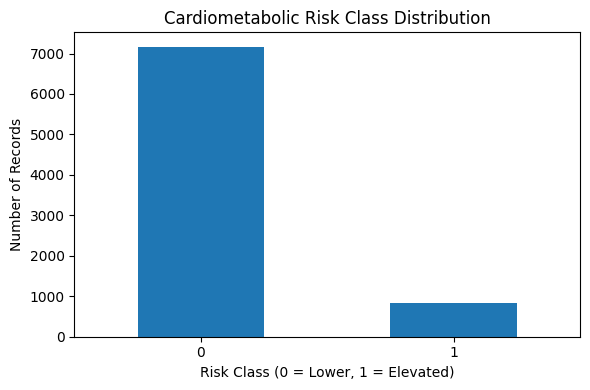

In [15]:

import matplotlib.pyplot as plt

target = "elevated_cardiometabolic_risk"

target_counts = df[target].value_counts().sort_index()
target_percent = df[target].value_counts(
    normalize=True
).sort_index() * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percent.round(2)
})

display(target_summary)

# Visualize class distribution
ax = target_counts.plot(
    kind="bar",
    figsize=(6, 4)
)

ax.set_title("Cardiometabolic Risk Class Distribution")
ax.set_xlabel("Risk Class (0 = Lower, 1 = Elevated)")
ax.set_ylabel("Number of Records")
ax.set_xticklabels(["0", "1"], rotation=0)

plt.tight_layout()
plt.show()


### Step 13 — Findings and Conclusion

- Lower-risk patients (Class 0): **7,165 (89.56%)**
- Elevated-risk patients (Class 1): **835 (10.44%)**
- The target variable shows significant class imbalance.

**Conclusion:** Accuracy alone will not adequately measure model performance. Recall, precision, F1-score, PR-AUC, and the confusion matrix will be important.

**Decision:** Use stratified data splitting to preserve class proportions. Evaluate appropriate imbalance-handling strategies during model development.

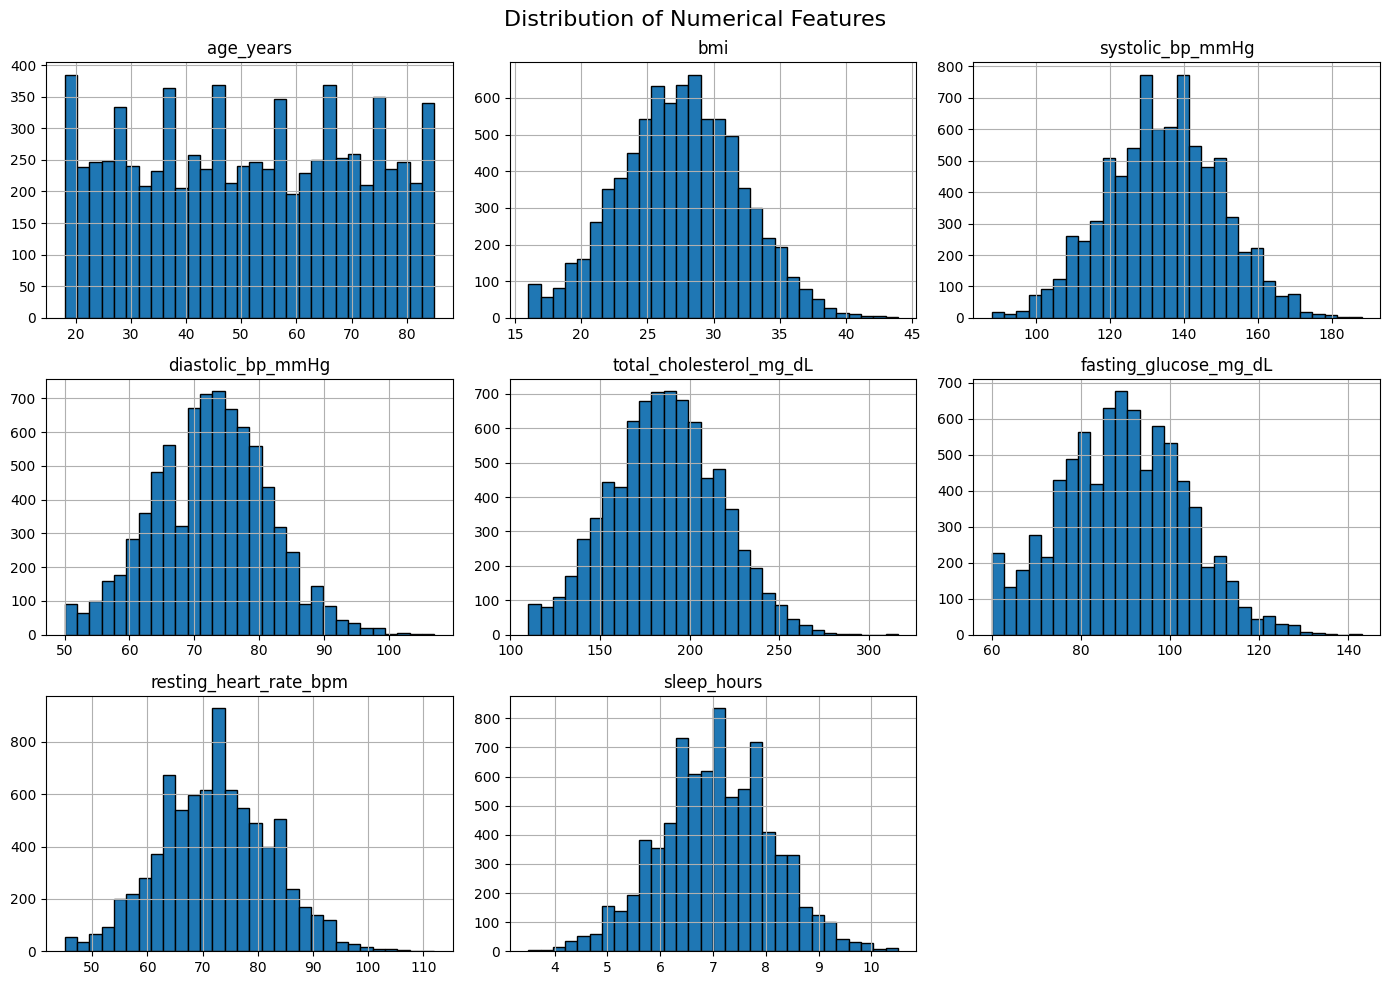

In [16]:

# Visualize numerical feature distributions
df[numerical_columns].hist(
    bins=30,
    figsize=(14, 10),
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


### Step 14 — Findings and Conclusion

- Age shows a broadly uniform distribution with some frequency peaks.
- BMI, blood pressure, cholesterol, fasting glucose, resting heart rate, and sleep duration show approximately bell-shaped distributions.
- Fasting glucose and BMI exhibit some higher-end observations.
- No clearly severe distributional anomalies are evident from the visible histograms.

**Conclusion:** Most numerical features appear reasonably distributed for ANN development. No log transformations are justified based on these histograms alone.

**Decision:** Retain the original feature values for now. Feature scaling will be performed later using training data only.

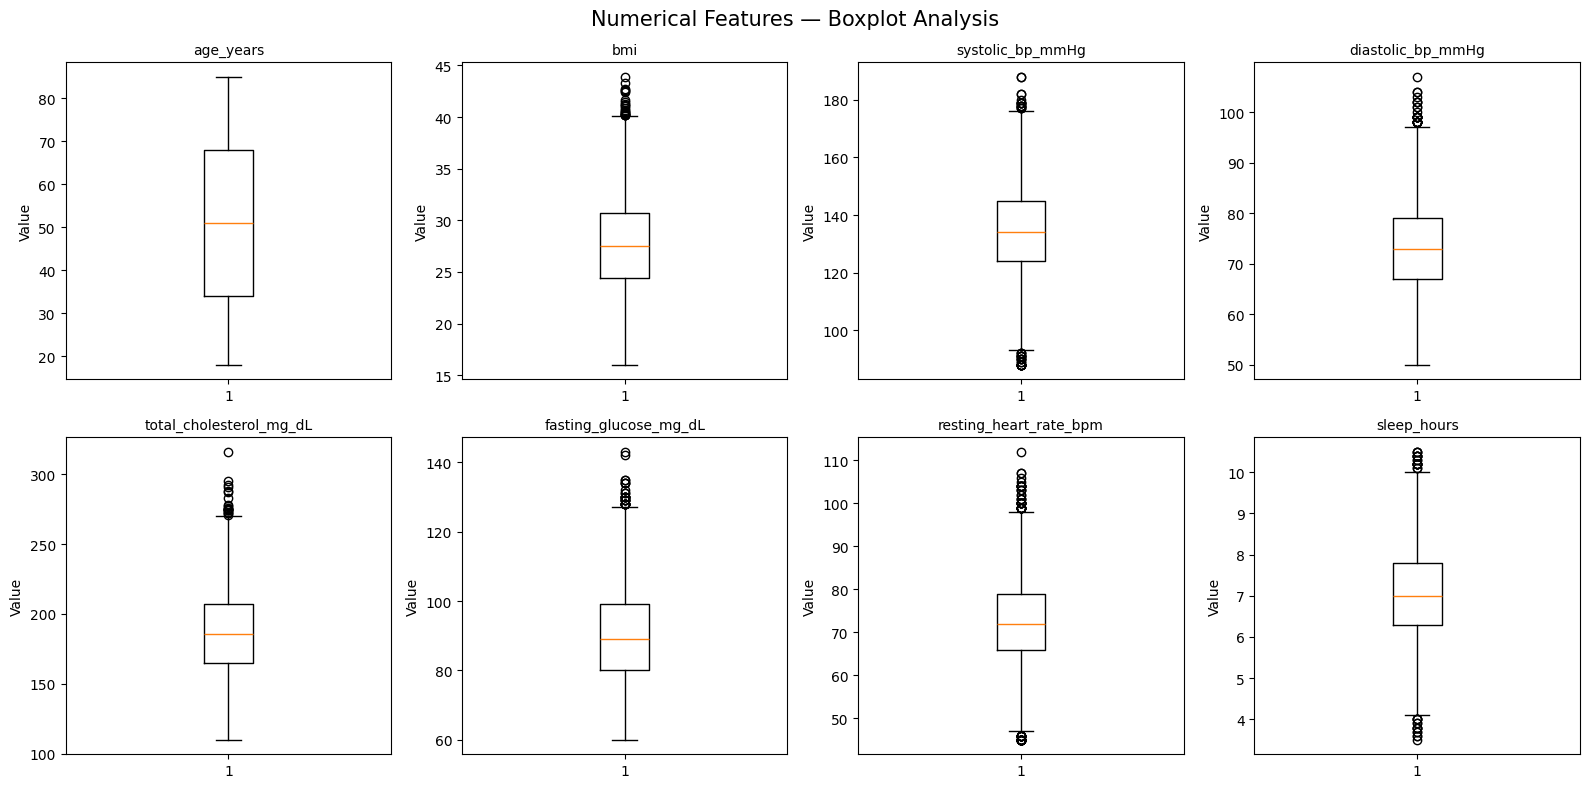

In [17]:

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, col in zip(axes.flatten(), numerical_columns):
    ax.boxplot(df[col].dropna())
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("Value")

plt.suptitle(
    "Numerical Features — Boxplot Analysis",
    fontsize=15
)

plt.tight_layout()
plt.show()


### Step 15 — Boxplot Findings

- Age contains no IQR outliers.
- BMI, blood pressure, cholesterol, glucose, resting heart rate, and sleep duration contain potential outliers.
- These observations are consistent with the earlier IQR analysis.

**Conclusion:** No outlier removal or capping will be performed at this stage because extreme health measurements may carry useful predictive information.

**Decision:** Retain the original observations and assess their relationships with the target during further EDA.

In [18]:

# Compare numerical features between risk classes
risk_comparison = df.groupby(
    "elevated_cardiometabolic_risk"
)[numerical_columns].agg(["mean", "median"])

display(risk_comparison.round(2).T)


elevated_cardiometabolic_risk        0       1
age_years               mean     49.52   66.69
                        median   49.00   71.00
bmi                     mean     27.29   29.14
                        median   27.30   29.00
systolic_bp_mmHg        mean    133.02  144.53
                        median  133.00  145.00
diastolic_bp_mmHg       mean     72.14   75.47
                        median   72.00   75.00
total_cholesterol_mg_dL mean    183.98  204.67
                        median  184.00  205.00
fasting_glucose_mg_dL   mean     88.81   95.95
                        median   89.00   95.00
resting_heart_rate_bpm  mean     72.30   72.71
                        median   72.00   73.00
sleep_hours             mean      7.04    6.97
                        median    7.00    7.00

### Step 16 — Findings and Conclusion

- Elevated-risk individuals have higher average age (66.69 vs 49.52 years).
- Systolic blood pressure, cholesterol, BMI, and fasting glucose are also higher in the elevated-risk group.
- Resting heart rate and sleep duration show relatively small differences between classes.
- Median values generally support the observed differences in group averages.

**Conclusion:** Several numerical features show associations with cardiometabolic risk classification, particularly age, blood pressure, and cholesterol.

These findings are descriptive and do not establish causation or feature importance in the ANN.

In [19]:

categorical_features = [
    "sex_female",
    "smoking_current",
    "family_history_cardiometabolic",
    "physical_activity_level",
    "stress_level_1_to_5"
]

for col in categorical_features:
    print(f"\n{col}")

    summary = df.groupby(col)[
        "elevated_cardiometabolic_risk"
    ].agg(
        Total="count",
        Elevated_Risk="sum",
        Risk_Rate="mean"
    )

    summary["Risk_Rate"] = (
        summary["Risk_Rate"] * 100
    ).round(2)

    display(summary)



sex_female


,Total,Elevated_Risk,Risk_Rate
sex_female,,,
0,3938,449,11.4
1,4062,386,9.5



smoking_current


,Total,Elevated_Risk,Risk_Rate
smoking_current,,,
0,6354,548,8.62
1,1646,287,17.44



family_history_cardiometabolic


,Total,Elevated_Risk,Risk_Rate
family_history_cardiometabolic,,,
0,5666,491,8.67
1,2334,344,14.74



physical_activity_level


,Total,Elevated_Risk,Risk_Rate
physical_activity_level,,,
0,1435,183,12.75
1,2520,258,10.24
2,2766,290,10.48
3,1279,104,8.13



stress_level_1_to_5


,Total,Elevated_Risk,Risk_Rate
stress_level_1_to_5,,,
1,980,64,6.53
2,1595,162,10.16
3,2530,261,10.32
4,1916,212,11.06
5,979,136,13.89


### Step 17 — Findings and Conclusion

- Current smokers have higher elevated-risk prevalence (17.44%) than non-smokers (8.62%).
- Individuals with a positive family history show higher elevated-risk prevalence (14.74%) than those without (8.67%).
- Elevated-risk prevalence generally increases with stress level, from 6.53% at Level 1 to 13.89% at Level 5.
- Physical activity Level 0 has the highest elevated-risk prevalence (12.75%), while Level 3 has the lowest (8.13%).
- A smaller difference is observed between the two sex categories.

**Conclusion:** Smoking, family history, stress level, and physical activity categories show associations with the target. These features should be retained for further analysis.

These are descriptive findings from synthetic data, not causal or clinically validated conclusions.

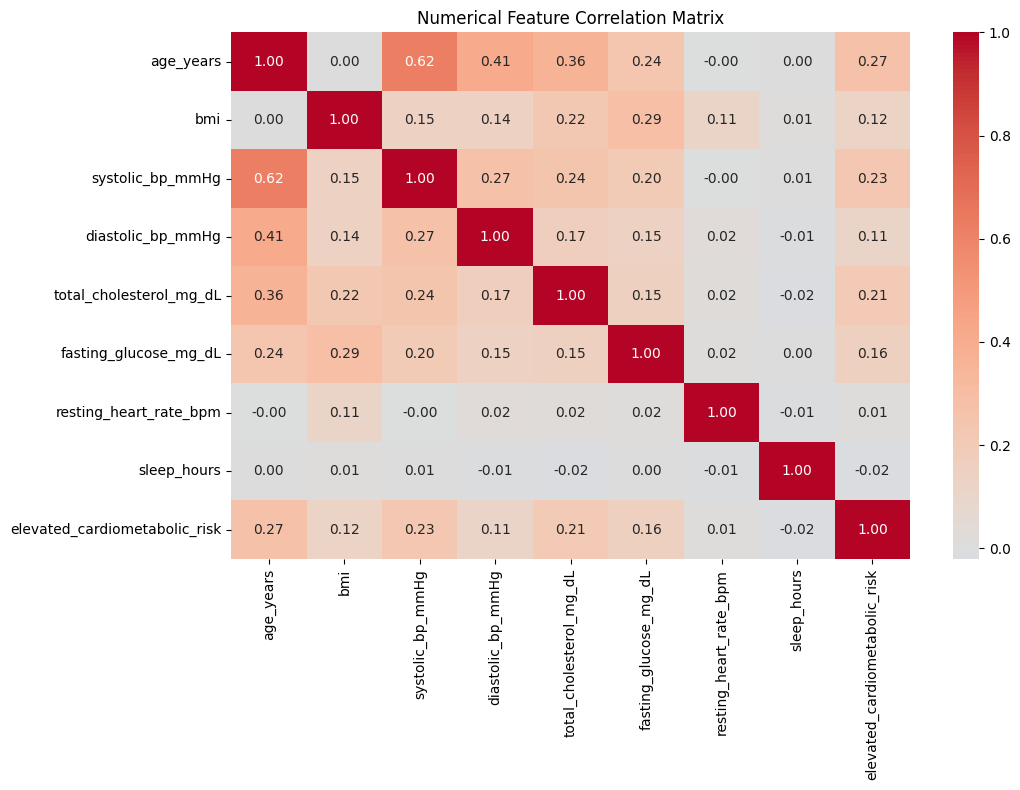

In [20]:

import seaborn as sns

correlation_columns = numerical_columns + [
    "elevated_cardiometabolic_risk"
]

corr_matrix = df[correlation_columns].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.show()


### Step 18 — Correlation Analysis Findings

- Age (+0.27), systolic BP (+0.23), and cholesterol (+0.21) have the strongest positive correlations with the target among numerical features.
- Resting heart rate (+0.01) and sleep duration (-0.02) show negligible linear correlations with the target.
- Age and systolic BP have a relatively strong positive correlation (+0.62).
- No numerical feature shows a very strong linear correlation with the target.

**Conclusion:** Several numerical features are associated with elevated cardiometabolic risk, but their individual linear correlations are modest.

**Decision:** Retain all features for now because neural networks can learn nonlinear relationships and feature interactions. No features will be dropped solely based on Pearson correlation.

In [21]:

target = "elevated_cardiometabolic_risk"

features = df.drop(columns=[target])

# Check for features identical to the target
identical_features = [
    col for col in features.columns
    if df[col].equals(df[target])
]

print("Features identical to target:", identical_features)

# Check for features with no category/value overlap
# between target classes
for col in features.columns:
    class_0_values = set(df.loc[df[target] == 0, col])
    class_1_values = set(df.loc[df[target] == 1, col])

    if class_0_values.isdisjoint(class_1_values):
        print("Potential leakage / perfect separation:", col)


Features identical to target: []


### Step 19 — Target Leakage Screening Findings

- No input feature is identical to the target variable.
- No individual feature completely separates the two target classes based on the observed values.
- No obvious direct target leakage was detected by these initial checks.

**Conclusion:** The dataset passes the initial leakage screening. However, target-generation rules and feature availability must still be considered before declaring the dataset leakage-free.

In [22]:

# Correlations among numerical input features
feature_corr = df[numerical_columns].corr().abs()

# Keep only the upper triangle (excluding diagonal)
upper_triangle = feature_corr.where(
    np.triu(
        np.ones(feature_corr.shape),
        k=1
    ).astype(bool)
)

# Find feature pairs with correlation >= 0.80
high_corr_pairs = upper_triangle.stack()
high_corr_pairs = high_corr_pairs[
    high_corr_pairs >= 0.80
]

print("Highly Correlated Feature Pairs (>= 0.80):")
print(high_corr_pairs if not high_corr_pairs.empty else "None found")


Highly Correlated Feature Pairs (>= 0.80):
None found


### Step 20 — Multicollinearity Findings

- No numerical feature pairs have an absolute Pearson correlation ≥ 0.80.
- Age and systolic BP show the strongest observed correlation (+0.62).
- No severe pairwise linear multicollinearity was identified using the selected threshold.

**Conclusion:** No numerical features need to be removed based on this screening. All 13 input features will be retained for further investigation.

This check does not rule out nonlinear or multivariable dependencies.

In [23]:

outlier_class_results = []

for col in numerical_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_mask = (df[col] < lower) | (df[col] > upper)

    for risk_class in [0, 1]:
        class_mask = df[target] == risk_class

        outlier_count = (outlier_mask & class_mask).sum()
        class_count = class_mask.sum()

        outlier_class_results.append({
            "Feature": col,
            "Risk Class": risk_class,
            "Outlier Count": int(outlier_count),
            "Outlier Rate (%)": round(
                outlier_count / class_count * 100, 2
            )
        })

outlier_by_class = pd.DataFrame(outlier_class_results)

display(
    outlier_by_class.pivot(
        index="Feature",
        columns="Risk Class",
        values=["Outlier Count", "Outlier Rate (%)"]
    )
)


Outlier Count       Outlier Rate (%)      
Risk Class                          0     1                0     1
Feature                                                           
age_years                         0.0   0.0             0.00  0.00
bmi                              16.0   6.0             0.22  0.72
diastolic_bp_mmHg                20.0   9.0             0.28  1.08
fasting_glucose_mg_dL            19.0  10.0             0.27  1.20
resting_heart_rate_bpm           71.0   9.0             0.99  1.08
sleep_hours                      31.0   3.0             0.43  0.36
systolic_bp_mmHg                 29.0  11.0             0.40  1.32
total_cholesterol_mg_dL          15.0   5.0             0.21  0.60

### Step 21 — Outlier Distribution Findings

- Class 1 has higher outlier rates for BMI, blood pressure, cholesterol, and fasting glucose.
- Systolic BP has the highest outlier rate among Class 1 observations (1.32%).
- Resting heart rate has similar outlier rates in both classes.
- Sleep duration has a slightly higher outlier rate in Class 0.

**Conclusion:** Some extreme measurements are more common among elevated-risk observations, suggesting they may contain useful predictive information.

**Decision:** Retain the outliers rather than automatically removing or capping them. Outlier treatment will be reconsidered only if training diagnostics justify it.

In [24]:

feature_columns = df.drop(columns=[target]).columns.tolist()

# Count distinct target labels for identical feature combinations
label_counts = (
    df.groupby(feature_columns)[target]
    .nunique()
)

conflicting_groups = label_counts[label_counts > 1]

print("Conflicting feature combinations:", len(conflicting_groups))

print(
    "Total records in conflicting groups:",
    int(
        df.set_index(feature_columns)
          .index.isin(conflicting_groups.index)
          .sum()
    )
)


Conflicting feature combinations: 0
Total records in conflicting groups: 0


### Step 22 — Feature-Target Consistency Findings

- No identical input feature combinations have conflicting target labels.
- No records were identified with contradictory labels for exactly matching inputs.

**Conclusion:** The dataset passes the exact feature-target consistency check. No corrections are required based on this test.

This does not establish that the target labels are clinically valid.

In [25]:

# Create a working copy without modifying the original
df_clean = df.copy()

print("Original Dataset:", df.shape)
print("Working Dataset:", df_clean.shape)

print("Missing Values:", df_clean.isna().sum().sum())
print("Duplicate Records:", df_clean.duplicated().sum())
print("Infinite Values:",
      np.isinf(df_clean.select_dtypes(include=np.number))
      .sum().sum())

print("All original values retained:", df_clean.equals(df))


Original Dataset: (8000, 14)
Working Dataset: (8000, 14)
Missing Values: 0
Duplicate Records: 0
Infinite Values: 0
All original values retained: True


### Step 23 — Data Cleaning Summary

**Findings:**
- Missing values: 0
- Duplicate records: 0
- Infinite values: 0
- Invalid records detected by numerical and categorical checks: 0
- Records removed: 0
- Records retained: 8,000

**Cleaning Decisions:**
- No missing-value imputation was required.
- No duplicate removal was required.
- Potential IQR outliers were retained because they may contain useful predictive information.
- A separate working DataFrame (`df_clean`) was created without modifying the original dataset.

**Conclusion:** The dataset passed the performed structural and value-quality checks. No cleaning transformations were necessary.

Further checks concerning target-generation rules and feature availability are required before model development.

In [26]:

print("Input Features:")
for col in df_clean.drop(columns=[target]).columns:
    print("-", col)

print("\nTarget:", target)
print("\nDataset Type: Synthetic")
print("Patient Identifier Available: No")
print("Observation Timestamp Available: No")
print("Target Generation Formula Available: Not established")


Input Features:
- age_years
- sex_female
- bmi
- systolic_bp_mmHg
- diastolic_bp_mmHg
- total_cholesterol_mg_dL
- fasting_glucose_mg_dL
- resting_heart_rate_bpm
- smoking_current
- family_history_cardiometabolic
- physical_activity_level
- sleep_hours
- stress_level_1_to_5

Target: elevated_cardiometabolic_risk

Dataset Type: Synthetic
Patient Identifier Available: No
Observation Timestamp Available: No
Target Generation Formula Available: Not established


### Step 24 — Dataset Metadata and Limitations

- The dataset contains 13 input features and one binary target.
- All available predictors represent health or lifestyle measurements.
- No patient identifier is available to verify patient-level independence.
- No timestamp is available for temporal validation.
- The target-generation formula is not documented.

**Conclusion:** No direct leakage was identified during earlier screening, but target-generation leakage cannot be fully ruled out.

**Modeling Assumption:** Treat each row as an independent observation and use stratified random splitting. Model results will represent performance on this synthetic dataset, not clinically validated risk prediction.

In [27]:

# Separate input features and target
X = df_clean.drop(columns=["elevated_cardiometabolic_risk"])

y = df_clean["elevated_cardiometabolic_risk"]

print("Feature Matrix (X):", X.shape)
print("Target Vector (y):", y.shape)

print("\nTarget included in X:",
      "elevated_cardiometabolic_risk" in X.columns)


Feature Matrix (X): (8000, 13)
Target Vector (y): (8000,)

Target included in X: False


### Step 25 — Findings and Conclusion

- Feature matrix (`X`): 8,000 rows × 13 features.
- Target vector (`y`): 8,000 labels.
- Target variable successfully excluded from the input features.

**Conclusion:** Input features and target labels are correctly separated. The dataset is ready for train-validation-test splitting.

In [28]:

from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (5600, 13) (5600,)
Validation: (1200, 13) (1200,)
Testing: (1200, 13) (1200,)


### Step 26 — Findings and Conclusion

The dataset was divided using stratified random splitting (`random_state=42`).

- **Training:** 5,600 records (70%)
- **Validation:** 1,200 records (15%)
- **Testing:** 1,200 records (15%)

**Conclusion:** Training, validation, and test datasets were successfully created. Stratification was used to maintain approximately the same target-class proportions across all three sets.

Preprocessing will be fitted on training data only to prevent data leakage.

In [29]:

split_summary = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True) * 100,
    "Validation": y_val.value_counts(normalize=True) * 100,
    "Testing": y_test.value_counts(normalize=True) * 100
}).round(2)

split_summary.index.name = "Risk Class"

display(split_summary)

print("\nClass counts:")
print("Training:", y_train.value_counts().sort_index().to_dict())
print("Validation:", y_val.value_counts().sort_index().to_dict())
print("Testing:", y_test.value_counts().sort_index().to_dict())


,Training,Validation,Testing
Risk Class,,,
0,89.55,89.58,89.58
1,10.45,10.42,10.42



Class counts:
Training: {0: 5015, 1: 585}
Validation: {0: 1075, 1: 125}
Testing: {0: 1075, 1: 125}


### Step 27 — Stratified Split Findings

- **Training:** 89.55% Class 0, 10.45% Class 1
- **Validation:** 89.58% Class 0, 10.42% Class 1
- **Testing:** 89.58% Class 0, 10.42% Class 1

**Conclusion:** Stratified splitting successfully preserved the target-class distribution across all three datasets.

The data is ready for feature preprocessing. The minority class remains represented in each split.

In [30]:

numeric_features = [
    "age_years",
    "bmi",
    "systolic_bp_mmHg",
    "diastolic_bp_mmHg",
    "total_cholesterol_mg_dL",
    "fasting_glucose_mg_dL",
    "resting_heart_rate_bpm",
    "sleep_hours",
    "stress_level_1_to_5"
]

binary_features = [
    "sex_female",
    "smoking_current",
    "family_history_cardiometabolic"
]

categorical_features = [
    "physical_activity_level"
]

# Verify that every input feature is accounted for
all_features = (
    numeric_features +
    binary_features +
    categorical_features
)

print("Total assigned features:", len(all_features))
print("Missing features:", set(X_train.columns) - set(all_features))
print("Unexpected features:", set(all_features) - set(X_train.columns))
print("Duplicate assignments:", len(all_features) - len(set(all_features)))


Total assigned features: 13
Missing features: set()
Unexpected features: set()
Duplicate assignments: 0


### Step 28 — Feature Grouping Findings

- **9 numerical/ordinal features:** Selected for standardization.
- **3 binary features:** Retained as 0/1.
- **1 categorical feature:** Selected for one-hot encoding.
- All 13 input features are accounted for without duplication.

**Conclusion:** Feature groups are correctly defined and ready for preprocessing.

In [31]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features),
        ("binary", "passthrough", binary_features)
    ],
    remainder="drop"
)

print(preprocessor)


ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                 ['age_years', 'bmi', 'systolic_bp_mmHg',
                                  'diastolic_bp_mmHg',
                                  'total_cholesterol_mg_dL',
                                  'fasting_glucose_mg_dL',
                                  'resting_heart_rate_bpm', 'sleep_hours',
                                  'stress_level_1_to_5']),
                                ('categorical',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['physical_activity_level']),
                                ('binary', 'passthrough',
                                 ['sex_female', 'smoking_current',
                                  'family_history_cardiometabolic'])])


### Step 29 — Preprocessing Pipeline Findings

- **StandardScaler:** Assigned to 9 numerical/ordinal features.
- **OneHotEncoder:** Assigned to physical activity level.
- **Passthrough:** Preserves 3 binary features without modification.

**Conclusion:** The preprocessing pipeline has been successfully defined. No transformations have been applied yet.

The pipeline will be fitted using training data only to prevent data leakage.

In [32]:

# Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to validation and test
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

print("\nAll values finite:",
      np.isfinite(X_train_processed).all()
      and np.isfinite(X_val_processed).all()
      and np.isfinite(X_test_processed).all())


Training: (5600, 16)
Validation: (1200, 16)
Testing: (1200, 16)

All values finite: True


### Step 30 — Preprocessing Findings

- Training dataset: **5,600 × 16**
- Validation dataset: **1,200 × 16**
- Testing dataset: **1,200 × 16**
- All transformed values are finite (`True`).
- One-hot encoding expanded the original 13 features into 16 input features.
- The preprocessor was fitted only on training data.

**Conclusion:** All three datasets have been successfully transformed using the same preprocessing rules, preventing validation/test information from influencing the fitted scaler and encoder.

In [33]:

# Get transformed feature names
processed_feature_names = preprocessor.get_feature_names_out()

# Convert transformed training data into a DataFrame
X_train_check = pd.DataFrame(
    X_train_processed,
    columns=processed_feature_names
)

# Display first five preprocessed records
display(X_train_check.head())

# Verify numerical scaling
print("\nNumerical Feature Means:")
print(X_train_check.iloc[:, :9].mean().round(4))

print("\nNumerical Feature Standard Deviations:")
print(X_train_check.iloc[:, :9].std(ddof=0).round(4))

# Verify encoded and binary columns
print("\nEncoded/Binary Unique Values:")
for col in X_train_check.columns[9:]:
    print(col, sorted(X_train_check[col].unique()))


,numeric__age_years,numeric__bmi,numeric__systolic_bp_mmHg,numeric__diastolic_bp_mmHg,numeric__total_cholesterol_mg_dL,numeric__fasting_glucose_mg_dL,numeric__resting_heart_rate_bpm,numeric__sleep_hours,numeric__stress_level_1_to_5,categorical__physical_activity_level_0,categorical__physical_activity_level_1,categorical__physical_activity_level_2,categorical__physical_activity_level_3,binary__sex_female,binary__smoking_current,binary__family_history_cardiometabolic
0,0.541855,0.538299,0.689235,0.053374,0.410624,0.608360,1.380806,3.247872,-1.721577,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-1.393960,0.865562,-2.152972,-0.392734,-0.474402,0.752449,0.181393,1.372483,-1.721577,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,1.153165,0.407395,-0.021317,-0.281207,-0.376065,1.761065,-0.218411,0.528558,-0.881417,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,-0.731707,0.931014,-1.571612,0.722536,-0.638295,-0.040036,-0.118460,0.059711,-0.041258,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,-0.171340,-0.050772,0.043279,1.280170,0.640075,1.112669,-0.318362,0.153481,-0.041258,0.0,1.0,0.0,0.0,1.0,0.0,0.0



Numerical Feature Means:
numeric__age_years                  0.0
numeric__bmi                       -0.0
numeric__systolic_bp_mmHg          -0.0
numeric__diastolic_bp_mmHg         -0.0
numeric__total_cholesterol_mg_dL   -0.0
numeric__fasting_glucose_mg_dL     -0.0
numeric__resting_heart_rate_bpm     0.0
numeric__sleep_hours                0.0
numeric__stress_level_1_to_5        0.0
dtype: float64

Numerical Feature Standard Deviations:
numeric__age_years                  1.0
numeric__bmi                        1.0
numeric__systolic_bp_mmHg           1.0
numeric__diastolic_bp_mmHg          1.0
numeric__total_cholesterol_mg_dL    1.0
numeric__fasting_glucose_mg_dL      1.0
numeric__resting_heart_rate_bpm     1.0
numeric__sleep_hours                1.0
numeric__stress_level_1_to_5        1.0
dtype: float64

Encoded/Binary Unique Values:
categorical__physical_activity_level_0 [0.0, 1.0]
categorical__physical_activity_level_1 [0.0, 1.0]
categorical__physical_activity_level_2 [0.0, 1.0]
cat

### Step 31 — Preprocessing Verification Findings

- All nine numerical/ordinal features have training means approximately equal to 0 and standard deviations equal to 1.
- One-hot encoding produced four activity-level columns.
- Binary features retain their 0/1 representation.
- The preprocessed feature matrix contains 16 columns.

**Conclusion:** Standardization and encoding appear successful. The preprocessed training data is suitable for further TensorFlow input validation.

In [34]:

# Convert input features to float32
X_train_nn = X_train_processed.astype(np.float32)
X_val_nn = X_val_processed.astype(np.float32)
X_test_nn = X_test_processed.astype(np.float32)

# Convert targets to float32
y_train_nn = y_train.to_numpy(dtype=np.float32)
y_val_nn = y_val.to_numpy(dtype=np.float32)
y_test_nn = y_test.to_numpy(dtype=np.float32)

# Verify shapes and data types
for name, arr in [
    ("X_train", X_train_nn),
    ("X_val", X_val_nn),
    ("X_test", X_test_nn),
    ("y_train", y_train_nn),
    ("y_val", y_val_nn),
    ("y_test", y_test_nn)
]:
    print(f"{name}: Shape={arr.shape}, Dtype={arr.dtype}")


X_train: Shape=(5600, 16), Dtype=float32
X_val: Shape=(1200, 16), Dtype=float32
X_test: Shape=(1200, 16), Dtype=float32
y_train: Shape=(5600,), Dtype=float32
y_val: Shape=(1200,), Dtype=float32
y_test: Shape=(1200,), Dtype=float32


### Step 32 — TensorFlow Input Preparation Findings

- Training inputs: 5,600 × 16
- Validation inputs: 1,200 × 16
- Testing inputs: 1,200 × 16
- All input arrays and target arrays use `float32`.
- The original 13 features have been transformed into 16 ANN input features.

**Conclusion:** The datasets are correctly formatted for TensorFlow/Keras. Data preparation is complete, and the next phase is neural network development.

In [42]:

import tensorflow as tf
from tensorflow import keras

print("TensorFlow Version:", tf.__version__)
print("Keras Version:", keras.__version__)

print("TensorFlow CPU:", tf.config.list_physical_devices("CPU"))
print("TensorFlow GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow Version: 2.21.0
Keras Version: 3.15.1
TensorFlow CPU: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
TensorFlow GPU: []


### Step 33 — TensorFlow Environment Verification

- TensorFlow version: 2.21.0
- Keras version: 3.15.1
- CPU successfully detected.
- GPU unavailable in the current native Windows environment.

**Conclusion:** TensorFlow and Keras are working correctly. The environment is ready for ANN development using CPU execution.

## 5. ANN Development — Sequential API

### Step 34 — ANN Architecture Design

**Objective:** Build a feedforward neural network using the Keras Sequential API.

**Proposed Architecture:**
- Input: 16 preprocessed features
- Hidden Layer 1: 32 neurons, ReLU activation
- Hidden Layer 2: 16 neurons, ReLU activation
- Output Layer: 1 neuron, Sigmoid activation

**Why this design?**

ReLU hidden layers allow the network to learn nonlinear relationships between health indicators. The Sigmoid output is appropriate for binary classification.

The architecture is an initial baseline and will be evaluated using validation data before any modifications.

In [43]:

from tensorflow import keras
from tensorflow.keras import layers

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Build Sequential ANN
sequential_model = keras.Sequential([
    keras.Input(shape=(16,)),

    layers.Dense(32, activation="relu", name="hidden_layer_1"),

    layers.Dense(16, activation="relu", name="hidden_layer_2"),

    layers.Dense(1, activation="sigmoid", name="output_layer")
], name="Cardiometabolic_Sequential_ANN")

# Display model architecture
sequential_model.summary()


Model: "Cardiometabolic_Sequential_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,089 (4.25 KB)

 Trainable params: 1,089 (4.25 KB)

 Non-trainable params: 0 (0.00 B)

### Step 35 — Sequential ANN Model Findings

- Successfully created an ANN using the Keras Sequential API.
- Architecture: 16 input features → 32 neurons → 16 neurons → 1 output neuron.
- Hidden layers use ReLU activation.
- Output layer uses Sigmoid activation.
- Total trainable parameters: **1,089**.
- Non-trainable parameters: 0.

**Conclusion:** The ANN architecture has been successfully initialized and is ready for compilation. No training has been performed yet.

In [44]:

sequential_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss=keras.losses.BinaryCrossentropy(),

    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="pr_auc", curve="PR")
    ]
)

print("Sequential ANN compiled successfully!")

print("Optimizer:", sequential_model.optimizer.__class__.__name__)
print("Learning Rate:", sequential_model.optimizer.learning_rate.numpy())
print("Loss:", sequential_model.loss.__class__.__name__)


Sequential ANN compiled successfully!
Optimizer: Adam
Learning Rate: 0.001
Loss: BinaryCrossentropy


### Step 36 — Model Compilation Findings

- **Optimizer:** Adam
- **Learning Rate:** 0.001
- **Loss Function:** Binary Crossentropy
- **Evaluation Metrics:** Accuracy, Precision, Recall and PR-AUC

**Conclusion:** The Sequential ANN has been successfully compiled and is ready for training.

The optimizer will update weights and biases using gradients calculated through backpropagation. No training has occurred yet.

In [45]:

from sklearn.utils.class_weight import compute_class_weight

# Calculate class weights from training labels only
classes = np.unique(y_train_nn)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_nn
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class Weights:", class_weights)


Class Weights: {0: 0.5583250249252243, 1: 4.786324786324786}


### Step 37 — Class Weight Findings

- Class 0 weight: **0.5583**
- Class 1 weight: **4.7863**
- Class 1 receives approximately 8.57 times the weight of Class 0 during training.

**Conclusion:** Class weights were calculated using training data only to address the target imbalance.

These weights will be applied during model training. Their effectiveness will be assessed using validation metrics, particularly recall, precision and PR-AUC.

In [46]:

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    min_delta=0.001,
    restore_best_weights=True
)

epochs = 100
batch_size = 32

print("Maximum Epochs:", epochs)
print("Batch Size:", batch_size)
print("Steps per Epoch:", int(np.ceil(len(X_train_nn) / batch_size)))
print("Early Stopping Monitor:", early_stopping.monitor)
print("Patience:", early_stopping.patience)
print("Restore Best Weights:", early_stopping.restore_best_weights)


Maximum Epochs: 100
Batch Size: 32
Steps per Epoch: 175
Early Stopping Monitor: val_loss
Patience: 10
Restore Best Weights: True


### Step 38 — Training Configuration Findings

- Maximum epochs: **100**
- Batch size: **32**
- Training batches per epoch: **175**
- Early stopping monitors validation loss (`val_loss`).
- Patience: **10 epochs**
- Best model weights will be restored automatically.

**Conclusion:** Training settings and early stopping are configured. The model is ready to begin learning through forward propagation, backpropagation, and Adam optimization.

In [47]:

history_seq = sequential_model.fit(
    X_train_nn,
    y_train_nn,

    validation_data=(X_val_nn, y_val_nn),

    epochs=epochs,
    batch_size=batch_size,

    class_weight=class_weights,
    callbacks=[early_stopping],

    verbose=1
)


Epoch 1/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6707 - loss: 0.6356 - pr_auc: 0.1968 - precision: 0.1747 - recall: 0.5778 - val_accuracy: 0.6267 - val_loss: 0.6077 - val_pr_auc: 0.2352 - val_precision: 0.1876 - val_recall: 0.7760
Epoch 2/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6623 - loss: 0.5520 - pr_auc: 0.3070 - precision: 0.2077 - recall: 0.7932 - val_accuracy: 0.6683 - val_loss: 0.5892 - val_pr_auc: 0.2931 - val_precision: 0.2065 - val_recall: 0.7680
Epoch 3/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6936 - loss: 0.5311 - pr_auc: 0.3485 - precision: 0.2248 - recall: 0.7897 - val_accuracy: 0.6842 - val_loss: 0.5764 - val_pr_auc: 0.3120 - val_precision: 0.2165 - val_recall: 0.7760
Epoch 4/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7082 - loss: 0.5214 - pr_auc: 0.3673 - precision: 0.2347 - recall: 0.7932 - val_accuracy: 0.6975 - val_loss: 0.5692 - val_pr_auc: 0.3211 - val_precision: 0.2258 - val_recall: 0.7840
Epoc

### Step 39 — Sequential ANN Training Findings

- The ANN was trained using Adam, binary crossentropy, class weights, and early stopping.
- Training accuracy increased from 67.07% to 79.41% by epoch 40.
- Training loss decreased from 0.6356 to 0.4180.
- Validation loss decreased from 0.6077 to 0.5264.
- Validation recall at epoch 40 was 65.60%, with precision of 24.12%.
- Training and validation PR-AUC show signs of a growing performance gap.

**Conclusion:** The ANN successfully learned patterns from the training data. However, its generalization performance and precision–recall trade-off require further investigation.

The final selected model performance has not yet been evaluated.

In [48]:

history_df = pd.DataFrame(history_seq.history)

total_epochs = len(history_df)

best_epoch = history_df["val_loss"].idxmin() + 1
best_val_loss = history_df["val_loss"].min()

print("Total Epochs Trained:", total_epochs)
print("Best Epoch (Validation Loss):", best_epoch)
print("Best Validation Loss:", round(best_val_loss, 4))

print("\nMetrics at Best Epoch:")
display(
    history_df.iloc[[best_epoch - 1]].round(4)
)


Total Epochs Trained: 40
Best Epoch (Validation Loss): 37
Best Validation Loss: 0.526

Metrics at Best Epoch:


,accuracy,loss,pr_auc,precision,recall,val_accuracy,val_loss,val_pr_auc,val_precision,val_recall
36,0.7887,0.4259,0.4581,0.3093,0.8291,0.7483,0.526,0.3379,0.2435,0.672


### Step 40 — Training History Findings

- Training completed after **40 epochs**, before the maximum of 100.
- The lowest recorded validation loss was **0.5260 at epoch 37**.
- Validation accuracy at epoch 37: **74.83%**.
- Validation precision: **24.35%**.
- Validation recall: **67.20%**.
- Validation PR-AUC: **0.3379**.

**Conclusion:** The model learned meaningful patterns but shows a training-validation performance gap, suggesting possible overfitting.

Further analysis of learning curves is necessary before making any changes to the architecture.

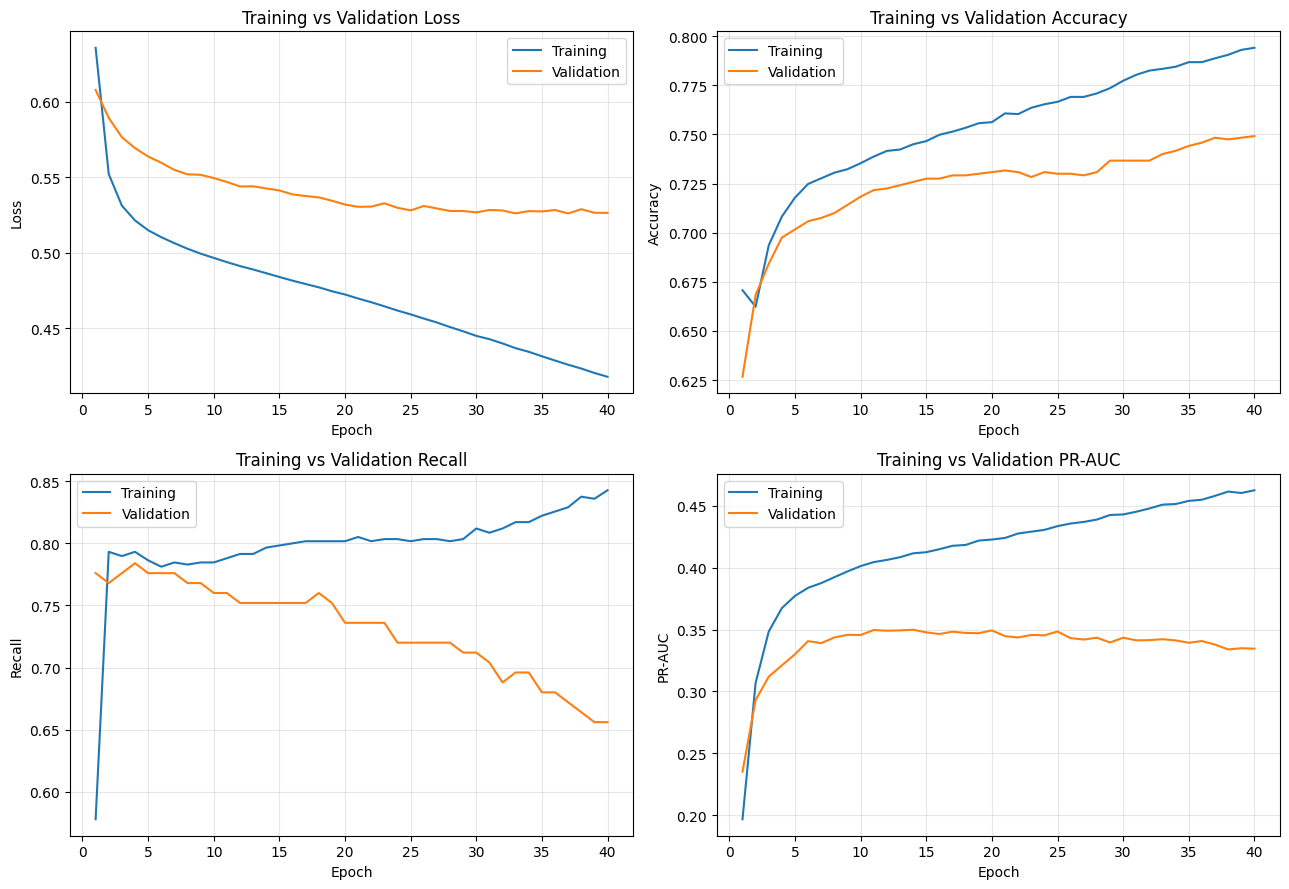

In [49]:

import matplotlib.pyplot as plt

metrics_to_plot = [
    ("loss", "Loss"),
    ("accuracy", "Accuracy"),
    ("recall", "Recall"),
    ("pr_auc", "PR-AUC")
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (metric, title) in zip(axes.flatten(), metrics_to_plot):
    ax.plot(
        history_df.index + 1,
        history_df[metric],
        label="Training"
    )

    ax.plot(
        history_df.index + 1,
        history_df[f"val_{metric}"],
        label="Validation"
    )

    ax.set_title(f"Training vs Validation {title}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Step 41 — Training Curve Analysis

**Observations:**
- Training loss decreases continuously, while validation loss gradually stabilizes.
- Training accuracy improves more than validation accuracy.
- Training recall increases, but validation recall declines during later epochs.
- Training PR-AUC continues improving, while validation PR-AUC peaks earlier and then slightly decreases.

**Conclusion:** The Sequential ANN shows signs of overfitting. Training performance improves while generalization performance stagnates or deteriorates.

**Next Action:** Evaluate the restored model on validation data and investigate the precision–recall trade-off before deciding whether architectural changes, regularization, or threshold adjustment are necessary.

In [50]:

# Evaluate the restored model using validation data
val_results = sequential_model.evaluate(
    X_val_nn,
    y_val_nn,
    verbose=0,
    return_dict=True
)

print("Restored Sequential ANN — Validation Metrics")

for metric, value in val_results.items():
    print(f"{metric}: {value:.4f}")


Restored Sequential ANN — Validation Metrics
accuracy: 0.7367
loss: 0.5267
pr_auc: 0.3434
precision: 0.2412
recall: 0.7120


### Step 42 — Restored Model Validation Findings

- Validation accuracy: **73.67%**
- Validation loss: **0.5267**
- Precision: **24.12%**
- Recall: **71.20%**
- PR-AUC: **0.3434**

**Conclusion:** The restored Sequential ANN detects 71.20% of elevated-risk observations at the default classification threshold of 0.5, but precision is relatively low.

The results indicate a trade-off between detecting elevated-risk cases and generating false-positive predictions.

**Next Action:** Examine the confusion matrix to understand the actual numbers of correct predictions, false positives, and false negatives before making model improvements.

True Negatives: 795
False Positives: 280
False Negatives: 36
True Positives: 89


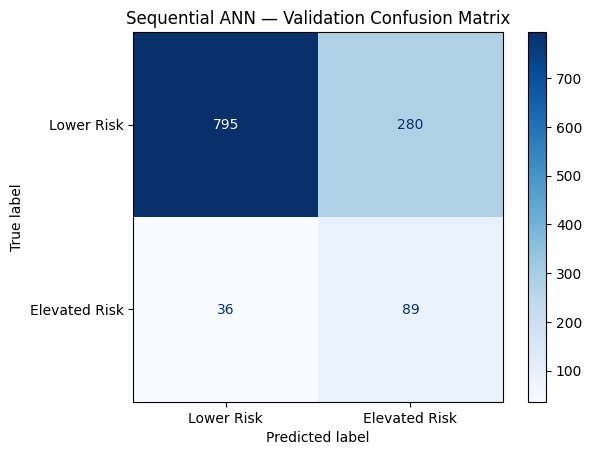

In [51]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict probabilities
val_probabilities = sequential_model.predict(
    X_val_nn,
    verbose=0
).ravel()

# Convert probabilities to class labels
val_predictions = (val_probabilities >= 0.5).astype(int)

# Calculate confusion matrix
cm = confusion_matrix(
    y_val_nn,
    val_predictions,
    labels=[0, 1]
)

# Display results
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Lower Risk", "Elevated Risk"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Sequential ANN — Validation Confusion Matrix")
plt.show()


### Step 43 — Confusion Matrix Findings

**Validation Confusion Matrix:**
- True Negatives (TN): 795
- False Positives (FP): 280
- False Negatives (FN): 36
- True Positives (TP): 89

**Findings:**
- The model correctly identifies 89 of 125 elevated-risk cases.
- It misses 36 elevated-risk cases.
- It incorrectly classifies 280 lower-risk cases as elevated risk.
- Recall is 71.20%, while precision is 24.12%.

**Conclusion:** The class-weighted Sequential ANN prioritizes elevated-risk detection but produces many false positives.

**Next Action:** Investigate the precision–recall trade-off using different classification thresholds on validation data. No model changes or test-set evaluation will be performed yet.

In [52]:

from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    predictions = (val_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val_nn, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_nn, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val_nn, predictions, zero_division=0
        ),
        "Predicted Positives": int(predictions.sum())
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1 Score,Predicted Positives
0,0.3,0.1852,0.864,0.3051,583
1,0.4,0.2089,0.792,0.3306,474
2,0.5,0.2412,0.712,0.3603,369
3,0.6,0.2821,0.616,0.3869,273
4,0.7,0.3026,0.472,0.3688,195


### Step 44 — Classification Threshold Analysis

- Lower thresholds increase recall but reduce precision.
- Higher thresholds generally increase precision while reducing recall.
- Threshold 0.3 achieves the highest recall among those tested (86.40%).
- Threshold 0.6 achieves the highest F1-score among those tested (0.3869).
- Threshold 0.5 provides 71.20% recall and 24.12% precision.

**Conclusion:** Classification threshold selection significantly affects the balance between false positives and false negatives.

**Decision:** Do not finalize a threshold yet. The choice should reflect the project's evaluation objective and be based on validation data only.

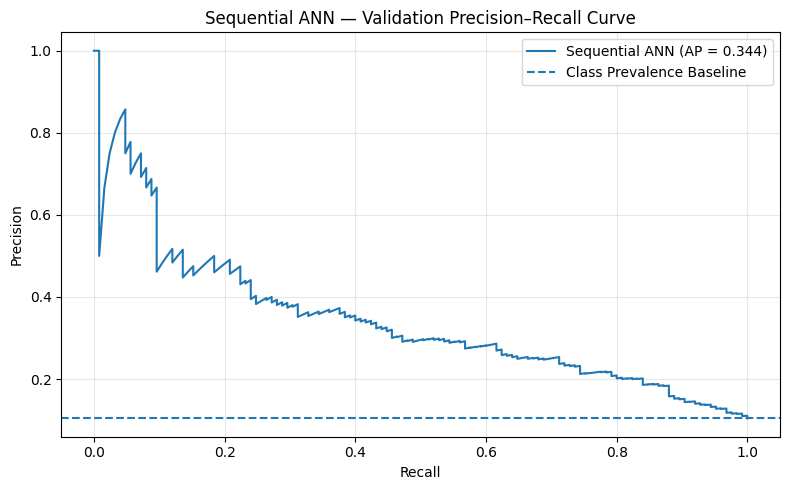

Average Precision: 0.3443


In [53]:

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision, recall, thresholds = precision_recall_curve(
    y_val_nn,
    val_probabilities
)

ap_score = average_precision_score(
    y_val_nn,
    val_probabilities
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision,
    label=f"Sequential ANN (AP = {ap_score:.3f})"
)

plt.axhline(
    y=y_val_nn.mean(),
    linestyle="--",
    label="Class Prevalence Baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Sequential ANN — Validation Precision–Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Average Precision:", round(ap_score, 4))


### Step 45 — Precision–Recall Curve Findings

- Average Precision (AP): **0.3443**
- Positive-class prevalence baseline: **0.1042**
- Precision generally decreases as recall increases.
- The model performs better than the class-prevalence baseline in average precision.

**Conclusion:** The Sequential ANN demonstrates predictive discrimination for elevated-risk cases, but precision remains limited at higher recall levels.

**Decision:** Retain these results as our initial Sequential ANN baseline and investigate improvements using validation data. The test set remains untouched.

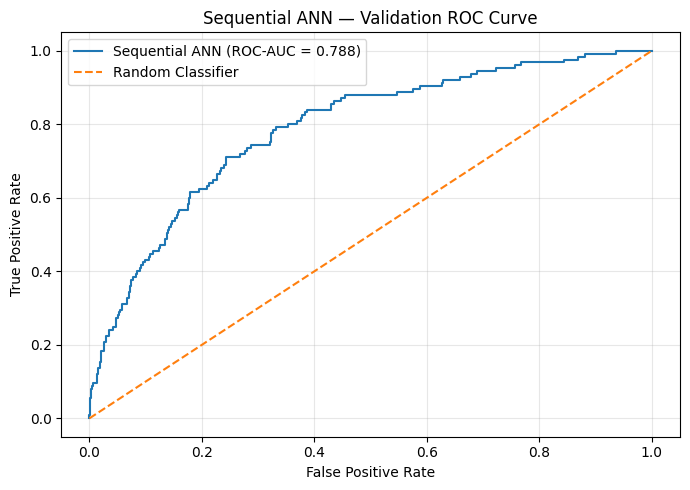

ROC-AUC: 0.7885


In [54]:

from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr, tpr, roc_thresholds = roc_curve(
    y_val_nn,
    val_probabilities
)

# Calculate ROC-AUC
roc_auc = roc_auc_score(
    y_val_nn,
    val_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Sequential ANN (ROC-AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Sequential ANN — Validation ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("ROC-AUC:", round(roc_auc, 4))


### Step 46 — ROC-AUC Evaluation Findings

- Validation ROC-AUC: **0.7885**
- The ROC curve remains above the random-classifier reference line.
- The model demonstrates reasonable discrimination between lower-risk and elevated-risk observations.
- Average Precision (0.3443) indicates that identifying the minority class precisely remains challenging.

**Conclusion:** The Sequential ANN has learned useful predictive patterns, but there is room to improve minority-class detection and generalization.

The results are based on validation data, not the untouched test set.

In [55]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

sequential_baseline = {
    "Model": "Sequential ANN — Baseline",
    "Threshold": 0.5,
    "Accuracy": accuracy_score(y_val_nn, val_predictions),
    "Precision": precision_score(y_val_nn, val_predictions),
    "Recall": recall_score(y_val_nn, val_predictions),
    "F1 Score": f1_score(y_val_nn, val_predictions),
    "Average Precision": average_precision_score(
        y_val_nn, val_probabilities
    ),
    "ROC-AUC": roc_auc_score(
        y_val_nn, val_probabilities
    )
}

baseline_df = pd.DataFrame([sequential_baseline])

display(baseline_df.round(4))


,Model,Threshold,Accuracy,Precision,Recall,F1 Score,Average Precision,ROC-AUC
0,Sequential ANN — Baseline,0.5,0.7367,0.2412,0.712,0.3603,0.3443,0.7885


### Step 47 — Sequential ANN Baseline Results

The baseline Sequential ANN achieved the following validation performance:

- Accuracy: **73.67%**
- Precision: **24.12%**
- Recall: **71.20%**
- F1-score: **0.3603**
- Average Precision: **0.3443**
- ROC-AUC: **0.7885**

**Conclusion:** The ANN demonstrates useful predictive discrimination but shows signs of overfitting and a substantial number of false positives.

These results will serve as the baseline for evaluating model improvements and comparing Sequential and Functional API implementations.

The test dataset remains untouched.

In [56]:

from tensorflow.keras import regularizers

tf.keras.utils.set_random_seed(42)

regularized_model = keras.Sequential([
    keras.Input(shape=(X_train_nn.shape[1],)),

    layers.Dense(
        32,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.2),

    layers.Dense(
        16,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid")

], name="Regularized_Sequential_ANN")

regularized_model.summary()


Model: "Regularized_Sequential_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,089 (4.25 KB)

 Trainable params: 1,089 (4.25 KB)

 Non-trainable params: 0 (0.00 B)

### Step 48 — Regularized ANN Architecture Findings

- Created a new Sequential ANN with two hidden layers containing 32 and 16 neurons.
- Added L2 regularization (`0.001`) to both hidden layers.
- Added Dropout (`0.2`) after each hidden layer.
- Total trainable parameters: **1,089**.

**Conclusion:** The regularized ANN was successfully initialized. It retains the baseline architecture while introducing techniques intended to reduce overfitting.

The model has not yet been compiled or trained.

In [57]:

regularized_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss=keras.losses.BinaryCrossentropy(),

    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(
            name="pr_auc",
            curve="PR"
        )
    ]
)

print("Regularized ANN compiled successfully!")
print("Optimizer:", regularized_model.optimizer.__class__.__name__)
print("Learning Rate:", regularized_model.optimizer.learning_rate.numpy())
print("Loss:", regularized_model.loss.__class__.__name__)


Regularized ANN compiled successfully!
Optimizer: Adam
Learning Rate: 0.001
Loss: BinaryCrossentropy


### Step 49 — Regularized ANN Compilation Findings

- Optimizer: Adam
- Learning rate: 0.001
- Loss function: Binary Crossentropy
- Metrics: Accuracy, Precision, Recall and PR-AUC

**Conclusion:** The regularized ANN was successfully compiled using the same optimization settings as the baseline Sequential ANN.

The model is ready for training with L2 regularization, Dropout, class weights and early stopping.

In [58]:

# Create a fresh early-stopping callback
early_stopping_reg = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    min_delta=0.001,
    restore_best_weights=True
)

# Train the regularized ANN
history_reg = regularized_model.fit(
    X_train_nn,
    y_train_nn,

    validation_data=(X_val_nn, y_val_nn),

    epochs=100,
    batch_size=32,

    class_weight=class_weights,
    callbacks=[early_stopping_reg],

    verbose=1
)


Epoch 1/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6637 - loss: 0.6633 - pr_auc: 0.2250 - precision: 0.1812 - recall: 0.6308 - val_accuracy: 0.6625 - val_loss: 0.6107 - val_pr_auc: 0.3239 - val_precision: 0.2071 - val_recall: 0.7920
Epoch 2/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6773 - loss: 0.6032 - pr_auc: 0.3036 - precision: 0.2123 - recall: 0.7709 - val_accuracy: 0.6750 - val_loss: 0.5937 - val_pr_auc: 0.3336 - val_precision: 0.2101 - val_recall: 0.7680
Epoch 3/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6761 - loss: 0.5911 - pr_auc: 0.3250 - precision: 0.2148 - recall: 0.7915 - val_accuracy: 0.6825 - val_loss: 0.5935 - val_pr_auc: 0.3430 - val_precision: 0.2156 - val_recall: 0.7760
Epoch 4/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6879 - loss: 0.5831 - pr_auc: 0.3441 - precision: 0.2192 - recall: 0.7761 - val_accuracy: 0.6842 - val_loss: 0.5884 - val_pr_auc: 0.3475 - val_precision: 0.2152 - val_recall: 0.7680
Epoc

### Step 50 — Regularized ANN Training Findings

- The regularized ANN completed 50 epochs.
- Training accuracy increased from 66.37% to 73.30%.
- Training loss decreased from 0.6633 to 0.5053.
- Validation accuracy at epoch 50 was 71.83%.
- Validation recall at epoch 50 was 76.80%.
- Validation PR-AUC at epoch 50 was 0.3520.

**Conclusion:** The regularized model successfully learned from the training data. Initial validation metrics suggest a different precision–recall trade-off compared with the baseline.

Further evaluation is required to determine whether regularization improved generalization.

In [59]:

# Inspect training history
reg_history_df = pd.DataFrame(history_reg.history)

best_reg_epoch = reg_history_df["val_loss"].idxmin() + 1

print("Total Epochs:", len(reg_history_df))
print("Lowest Validation Loss Epoch:", best_reg_epoch)
print(
    "Lowest Recorded Validation Loss:",
    round(reg_history_df["val_loss"].min(), 4)
)

# Evaluate restored model
reg_val_results = regularized_model.evaluate(
    X_val_nn,
    y_val_nn,
    verbose=0,
    return_dict=True
)

print("\nRestored Regularized ANN — Validation Metrics")

for metric, value in reg_val_results.items():
    print(f"{metric}: {value:.4f}")


Total Epochs: 50
Lowest Validation Loss Epoch: 40
Lowest Recorded Validation Loss: 0.5386

Restored Regularized ANN — Validation Metrics
accuracy: 0.7250
loss: 0.5386
pr_auc: 0.3533
precision: 0.2392
recall: 0.7520


### Step 51 — Regularized ANN Evaluation Findings

- Total training epochs: **50**
- Lowest recorded validation loss: **0.5386 at epoch 40**
- Validation accuracy: **72.50%**
- Precision: **23.92%**
- Recall: **75.20%**
- PR-AUC: **0.3533**

**Conclusion:** The regularized ANN achieved higher validation recall and PR-AUC than the baseline, with slightly lower accuracy and precision.

The improvements are modest and require further comparison. We cannot conclude that regularization consistently improves generalization based on one training run.


In [60]:

# Regularized model probabilities
reg_val_probs = regularized_model.predict(
    X_val_nn, verbose=0
).ravel()

reg_val_preds = (reg_val_probs >= 0.5).astype(int)

# Compare both models at the same threshold
comparison_results = []

for name, probs, preds in [
    ("Baseline Sequential ANN", val_probabilities, val_predictions),
    ("Regularized Sequential ANN", reg_val_probs, reg_val_preds)
]:
    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val_nn, preds),
        "Precision": precision_score(y_val_nn, preds),
        "Recall": recall_score(y_val_nn, preds),
        "F1 Score": f1_score(y_val_nn, preds),
        "Average Precision": average_precision_score(y_val_nn, probs),
        "ROC-AUC": roc_auc_score(y_val_nn, probs)
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,Average Precision,ROC-AUC
0,Baseline Sequential ANN,0.7367,0.2412,0.712,0.3603,0.3443,0.7885
1,Regularized Sequential ANN,0.7250,0.2392,0.752,0.3629,0.3595,0.8032


### Step 52 — Sequential ANN Model Comparison

The baseline and regularized Sequential ANNs were evaluated using the same validation dataset and a classification threshold of 0.5.

**Findings:**
- Recall improved from 71.20% to 75.20%.
- F1-score improved from 0.3603 to 0.3629.
- Average Precision improved from 0.3443 to 0.3595.
- ROC-AUC improved from 0.7885 to 0.8032.
- Accuracy and precision decreased slightly.

**Conclusion:** The regularized model achieved modest improvements in recall and threshold-independent ranking metrics.

**Decision:** Retain both models for further comparison. The regularized ANN is the current preferred candidate based on validation recall and Average Precision, but final model selection has not been completed.

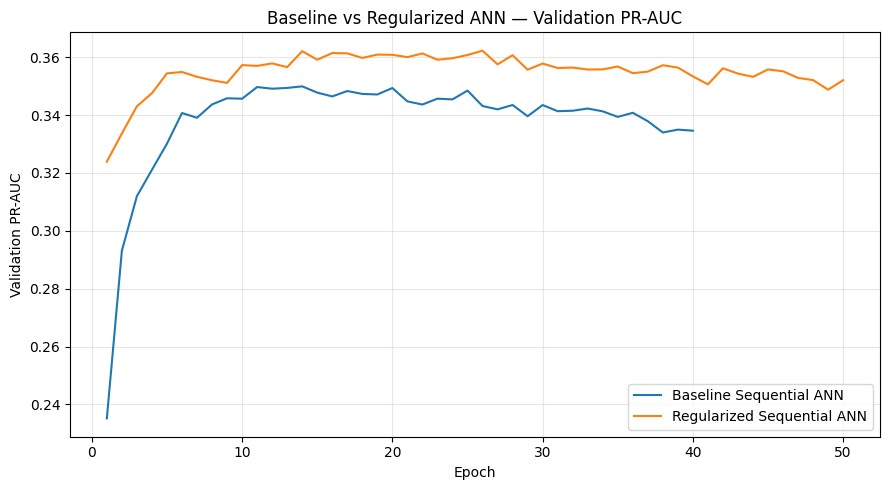

In [61]:

plt.figure(figsize=(9, 5))

# Baseline validation PR-AUC
plt.plot(
    range(1, len(history_seq.history["val_pr_auc"]) + 1),
    history_seq.history["val_pr_auc"],
    label="Baseline Sequential ANN"
)

# Regularized validation PR-AUC
plt.plot(
    range(1, len(history_reg.history["val_pr_auc"]) + 1),
    history_reg.history["val_pr_auc"],
    label="Regularized Sequential ANN"
)

plt.xlabel("Epoch")
plt.ylabel("Validation PR-AUC")
plt.title("Baseline vs Regularized ANN — Validation PR-AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Step 53 — Validation PR-AUC Comparison

**Findings:**
- The baseline ANN reaches a peak validation PR-AUC of approximately 0.35 before gradually declining.
- The regularized ANN reaches approximately 0.36 and maintains more stable validation performance.
- The regularized model consistently achieves higher validation PR-AUC across the displayed epochs.

**Conclusion:** Adding L2 regularization and Dropout improved validation PR-AUC and training stability in this experiment.

**Decision:** Retain the regularized Sequential ANN as our current preferred model candidate based on validation Average Precision and recall. Further evaluation is required before final model selection.

## 6. ANN Development — Functional API

### Step 54 — Functional API Architecture

**Objective:** Develop an ANN using the Keras Functional API and compare it with the Sequential API.

**Why Functional API?**

The Functional API allows us to explicitly define connections between layers. Unlike the Sequential API, it also supports more complex architectures, including multiple inputs, multiple outputs, and branching networks.

**Initial Architecture:**
- Input: 16 preprocessed features
- Hidden Layer 1: 32 neurons, ReLU
- Hidden Layer 2: 16 neurons, ReLU
- Output Layer: 1 neuron, Sigmoid

**Approach:** First reproduce the baseline Sequential architecture using the Functional API. Later, explore a multi-input architecture and compare model performance.

In [62]:

# Set seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Define input
inputs = keras.Input(
    shape=(X_train_nn.shape[1],),
    name="patient_features"
)

# Hidden layers
x = layers.Dense(
    32,
    activation="relu",
    name="functional_hidden_1"
)(inputs)

x = layers.Dense(
    16,
    activation="relu",
    name="functional_hidden_2"
)(x)

# Output layer
outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="functional_output"
)(x)

# Create Functional API model
functional_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="Cardiometabolic_Functional_ANN"
)

functional_model.summary()


Model: "Cardiometabolic_Functional_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ patient_features (InputLayer)   │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_hidden_1 (Dense)     │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_hidden_2 (Dense)     │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_output (Dense)       │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,089 (4.25 KB)

 Trainable params: 1,089 (4.25 KB)

 Non-trainable params: 0 (0.00 B)

### Step 54 — Functional API Architecture Findings

- Successfully created an ANN using the Keras Functional API.
- Architecture: 16 inputs → 32 neurons → 16 neurons → 1 output.
- Hidden layers use ReLU; the output uses Sigmoid.
- Total trainable parameters: **1,089**.
- The architecture is equivalent to the baseline Sequential ANN.

**Conclusion:** The Functional API allows explicit connections between layers and supports more complex network structures. The model has been created but not trained.

In [63]:

functional_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="pr_auc", curve="PR")
    ]
)

print("Functional ANN compiled successfully!")
print("Optimizer:", functional_model.optimizer.__class__.__name__)
print("Learning Rate:", functional_model.optimizer.learning_rate.numpy())
print("Loss:", functional_model.loss.__class__.__name__)


Functional ANN compiled successfully!
Optimizer: Adam
Learning Rate: 0.001
Loss: BinaryCrossentropy


### Step 55 — Functional ANN Compilation Findings

- Optimizer: Adam
- Learning rate: 0.001
- Loss function: Binary Crossentropy
- Metrics: Accuracy, Precision, Recall and PR-AUC

**Conclusion:** The Functional ANN has been successfully compiled using the same architecture and optimization settings as the baseline Sequential ANN.

The model is ready for training.

In [64]:

# Create a separate early stopping callback
early_stopping_func = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    min_delta=0.001,
    restore_best_weights=True
)

# Train Functional ANN
history_func = functional_model.fit(
    X_train_nn,
    y_train_nn,

    validation_data=(X_val_nn, y_val_nn),

    epochs=100,
    batch_size=32,

    class_weight=class_weights,
    callbacks=[early_stopping_func],

    verbose=1
)


Epoch 1/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6707 - loss: 0.6356 - pr_auc: 0.1968 - precision: 0.1747 - recall: 0.5778 - val_accuracy: 0.6267 - val_loss: 0.6077 - val_pr_auc: 0.2352 - val_precision: 0.1876 - val_recall: 0.7760
Epoch 2/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6623 - loss: 0.5520 - pr_auc: 0.3070 - precision: 0.2077 - recall: 0.7932 - val_accuracy: 0.6683 - val_loss: 0.5892 - val_pr_auc: 0.2931 - val_precision: 0.2065 - val_recall: 0.7680
Epoch 3/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6936 - loss: 0.5311 - pr_auc: 0.3485 - precision: 0.2248 - recall: 0.7897 - val_accuracy: 0.6842 - val_loss: 0.5764 - val_pr_auc: 0.3120 - val_precision: 0.2165 - val_recall: 0.7760
Epoch 4/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7082 - loss: 0.5214 - pr_auc: 0.3673 - precision: 0.2347 - recall: 0.7932 - val_accuracy: 0.6975 - val_loss: 0.5692 - val_pr_auc: 0.3211 - val_precision: 0.2258 - val_recall: 0.7840
Epoc

### Step 56 — Functional ANN Training Findings

- The Functional ANN completed 40 epochs.
- Final training accuracy: 79.41%.
- Final training loss: 0.4180.
- Final validation accuracy: 74.92%.
- Final validation recall: 65.60%.
- Final validation PR-AUC: 0.3346.
- The observed training metrics match the baseline Sequential ANN.

**Conclusion:** The Functional ANN successfully learned using forward propagation, backpropagation and Adam optimization.

Both APIs produced identical training results in this experiment, supporting their computational equivalence for the same simple architecture.

The restored Functional ANN still requires validation evaluation.

In [65]:

# Generate validation probabilities
seq_val_probs = sequential_model.predict(
    X_val_nn, verbose=0
).ravel()

func_val_probs = functional_model.predict(
    X_val_nn, verbose=0
).ravel()

# Compare predictions
max_difference = np.max(
    np.abs(seq_val_probs - func_val_probs)
)

predictions_match = np.allclose(
    seq_val_probs,
    func_val_probs,
    rtol=1e-5,
    atol=1e-6
)

print("Maximum Probability Difference:", max_difference)
print("Predictions Match:", predictions_match)

# Evaluate Functional ANN
func_val_results = functional_model.evaluate(
    X_val_nn,
    y_val_nn,
    verbose=0,
    return_dict=True
)

print("\nFunctional ANN Validation Metrics:")
for metric, value in func_val_results.items():
    print(f"{metric}: {value:.4f}")


Maximum Probability Difference: 0.0
Predictions Match: True

Functional ANN Validation Metrics:
accuracy: 0.7367
loss: 0.5267
pr_auc: 0.3434
precision: 0.2412
recall: 0.7120


### Step 57 — Sequential vs Functional API Equivalence

**Findings:**
- Maximum prediction probability difference: **0.0**
- Prediction equivalence: **True**
- Both models achieved identical validation metrics.
- Both architectures contain **1,089 trainable parameters**.

**Conclusion:** The Sequential and Functional APIs produced numerically identical predictions for the equivalent ANN architecture in this experiment.

The main advantage of the Functional API is architectural flexibility, including multiple inputs, branching connections, and multiple outputs—not inherently better prediction accuracy.

In [66]:

# Group 1: Clinical measurements
clinical_features = [
    "numeric__age_years",
    "numeric__bmi",
    "numeric__systolic_bp_mmHg",
    "numeric__diastolic_bp_mmHg",
    "numeric__total_cholesterol_mg_dL",
    "numeric__fasting_glucose_mg_dL",
    "numeric__resting_heart_rate_bpm"
]

# Group 2: Lifestyle and other characteristics
other_features = [
    "numeric__sleep_hours",
    "numeric__stress_level_1_to_5",
    "categorical__physical_activity_level_0",
    "categorical__physical_activity_level_1",
    "categorical__physical_activity_level_2",
    "categorical__physical_activity_level_3",
    "binary__sex_female",
    "binary__smoking_current",
    "binary__family_history_cardiometabolic"
]

# Verify grouping
all_processed_features = list(preprocessor.get_feature_names_out())
grouped_features = clinical_features + other_features

print("Clinical features:", len(clinical_features))
print("Other features:", len(other_features))
print("Total grouped features:", len(grouped_features))

print(
    "Missing features:",
    set(all_processed_features) - set(grouped_features)
)

print(
    "Unexpected features:",
    set(grouped_features) - set(all_processed_features)
)

print(
    "Duplicate assignments:",
    len(grouped_features) - len(set(grouped_features))
)


Clinical features: 7
Other features: 9
Total grouped features: 16
Missing features: set()
Unexpected features: set()
Duplicate assignments: 0


In [67]:

# Get processed column names
feature_names = list(preprocessor.get_feature_names_out())

# Identify column positions
clinical_indices = [
    feature_names.index(col) for col in clinical_features
]

other_indices = [
    feature_names.index(col) for col in other_features
]

# Split training features into two branches
X_train_clinical = X_train_nn[:, clinical_indices]
X_train_other = X_train_nn[:, other_indices]

# Split validation features into two branches
X_val_clinical = X_val_nn[:, clinical_indices]
X_val_other = X_val_nn[:, other_indices]

# Verify dimensions
print("Training:")
print("Clinical:", X_train_clinical.shape)
print("Other:", X_train_other.shape)

print("\nValidation:")
print("Clinical:", X_val_clinical.shape)
print("Other:", X_val_other.shape)

# Verify that all original processed values are preserved
reconstructed_train = np.empty_like(X_train_nn)
reconstructed_train[:, clinical_indices] = X_train_clinical
reconstructed_train[:, other_indices] = X_train_other

print(
    "\nAll training values preserved:",
    np.array_equal(reconstructed_train, X_train_nn)
)


Training:
Clinical: (5600, 7)
Other: (5600, 9)

Validation:
Clinical: (1200, 7)
Other: (1200, 9)

All training values preserved: True


### Step 59 — Multi-Input Data Preparation Findings

- Clinical training data: **5,600 × 7**
- Other training data: **5,600 × 9**
- Clinical validation data: **1,200 × 7**
- Other validation data: **1,200 × 9**
- All training feature values were preserved.

**Conclusion:** The 16 preprocessed features have been correctly separated into two input groups without losing information or changing the original values.

The data is ready for a multi-input Functional ANN.

In [68]:

tf.keras.utils.set_random_seed(42)

# Branch 1: Clinical features
clinical_input = keras.Input(
    shape=(7,),
    name="clinical_input"
)

clinical_branch = layers.Dense(
    16,
    activation="relu",
    name="clinical_dense"
)(clinical_input)

# Branch 2: Other features
other_input = keras.Input(
    shape=(9,),
    name="other_input"
)

other_branch = layers.Dense(
    16,
    activation="relu",
    name="other_dense"
)(other_input)

# Combine both branches
combined = layers.Concatenate(
    name="feature_fusion"
)([clinical_branch, other_branch])

# Shared hidden layer
x = layers.Dense(
    16,
    activation="relu",
    name="shared_dense"
)(combined)

# Final prediction
output = layers.Dense(
    1,
    activation="sigmoid",
    name="risk_output"
)(x)

multi_input_model = keras.Model(
    inputs=[clinical_input, other_input],
    outputs=output,
    name="Multi_Input_Functional_ANN"
)

multi_input_model.summary()


Model: "Multi_Input_Functional_ANN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ clinical_input      │ (None, 7)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_input         │ (None, 9)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical_dense      │ (None, 16)        │        128 │ clinical_input[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other_dense (Dense) │ (None, 16)        │        160 │ other_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_fusion      │ (None, 32)        │          0 │ clinical_dense[0… │
│ (Concatenate)       │                   │            │ other_dense[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_dense        │ (None, 16)        │        528 │ feature_fusion[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ risk_output (Dense) │ (None, 1)         │         17 │ shared_dense[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

### Step 60 — Multi-Input Functional ANN Findings

- Created two input branches: Clinical (7 features) and Other (9 features).
- Each branch contains a Dense layer with 16 ReLU neurons.
- Concatenate combines both branch outputs into 32 features.
- A shared Dense layer processes the combined representation.
- The final Sigmoid layer predicts the binary target.
- Total trainable parameters: **833**.

**Conclusion:** The multi-input Functional ANN was successfully created. It demonstrates the Functional API's ability to process separate feature groups and combine their learned representations.

The model has not yet been compiled or trained.

In [69]:

multi_input_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(
            name="pr_auc",
            curve="PR"
        )
    ]
)

print("Multi-Input Functional ANN compiled successfully!")
print("Optimizer:", multi_input_model.optimizer.__class__.__name__)
print("Learning Rate:", multi_input_model.optimizer.learning_rate.numpy())
print("Loss:", multi_input_model.loss.__class__.__name__)


Multi-Input Functional ANN compiled successfully!
Optimizer: Adam
Learning Rate: 0.001
Loss: BinaryCrossentropy


### Step 61 — Multi-Input Functional ANN Compilation

- Optimizer: Adam
- Learning rate: 0.001
- Loss function: Binary Crossentropy
- Evaluation metrics: Accuracy, Precision, Recall and PR-AUC

**Conclusion:** The multi-input Functional ANN has been successfully compiled and is ready for training. Both branches will learn through backpropagation from the shared output loss.

In [70]:

# Fresh early stopping callback
early_stopping_multi = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    min_delta=0.001,
    restore_best_weights=True
)

# Train multi-input Functional ANN
history_multi = multi_input_model.fit(
    x={
        "clinical_input": X_train_clinical,
        "other_input": X_train_other
    },
    y=y_train_nn,

    validation_data=(
        {
            "clinical_input": X_val_clinical,
            "other_input": X_val_other
        },
        y_val_nn
    ),

    epochs=100,
    batch_size=32,

    class_weight=class_weights,
    callbacks=[early_stopping_multi],

    verbose=1
)


Epoch 1/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6346 - loss: 0.6410 - pr_auc: 0.2138 - precision: 0.1610 - recall: 0.5932 - val_accuracy: 0.6367 - val_loss: 0.6465 - val_pr_auc: 0.3098 - val_precision: 0.1909 - val_recall: 0.7680
Epoch 2/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6809 - loss: 0.5605 - pr_auc: 0.3086 - precision: 0.2102 - recall: 0.7453 - val_accuracy: 0.6767 - val_loss: 0.6043 - val_pr_auc: 0.3238 - val_precision: 0.2123 - val_recall: 0.7760
Epoch 3/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7080 - loss: 0.5409 - pr_auc: 0.3364 - precision: 0.2305 - recall: 0.7675 - val_accuracy: 0.6925 - val_loss: 0.5922 - val_pr_auc: 0.3264 - val_precision: 0.2202 - val_recall: 0.7680
Epoch 4/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7170 - loss: 0.5307 - pr_auc: 0.3517 - precision: 0.2393 - recall: 0.7846 - val_accuracy: 0.6908 - val_loss: 0.5859 - val_pr_auc: 0.3318 - val_precision: 0.2166 - val_recall: 0.7520
Epoc

### Step 62 — Multi-Input Functional ANN Training Findings

- Training completed after **36 epochs**.
- Training accuracy increased from 63.46% to 75.80%.
- Training loss decreased from 0.6410 to 0.4703.
- Training PR-AUC increased from 0.2138 to 0.4190.
- Validation PR-AUC at epoch 36 was 0.3393.
- Validation performance plateaued while training performance continued improving.

**Conclusion:** The multi-input Functional ANN successfully learned from both input branches, but its validation metrics suggest possible overfitting.

The restored model must be evaluated before comparing it with the earlier ANN architectures.

In [71]:

# Examine training history
multi_history_df = pd.DataFrame(history_multi.history)

best_multi_epoch = multi_history_df["val_loss"].idxmin() + 1

print("Total Epochs:", len(multi_history_df))
print("Lowest Validation Loss Epoch:", best_multi_epoch)
print(
    "Lowest Recorded Validation Loss:",
    round(multi_history_df["val_loss"].min(), 4)
)

# Evaluate the restored multi-input model
multi_val_results = multi_input_model.evaluate(
    x={
        "clinical_input": X_val_clinical,
        "other_input": X_val_other
    },
    y=y_val_nn,
    verbose=0,
    return_dict=True
)

print("\nRestored Multi-Input ANN — Validation Metrics")

for metric, value in multi_val_results.items():
    print(f"{metric}: {value:.4f}")


Total Epochs: 36
Lowest Validation Loss Epoch: 26
Lowest Recorded Validation Loss: 0.567

Restored Multi-Input ANN — Validation Metrics
accuracy: 0.7117
loss: 0.5670
pr_auc: 0.3428
precision: 0.2350
recall: 0.7840


### Step 63 — Multi-Input Functional ANN Evaluation

- Training epochs: **36**
- Lowest recorded validation loss: **0.5670 at epoch 26**
- Validation accuracy: **71.17%**
- Precision: **23.50%**
- Recall: **78.40%**
- PR-AUC: **0.3428**

**Conclusion:** The multi-input Functional ANN demonstrates useful minority-class detection, achieving higher recall at the default threshold than our earlier models.

However, its precision remains low, and its PR-AUC does not exceed that of the regularized Sequential ANN.

Final model selection requires a consistent comparison across all architectures.

In [72]:

# Generate multi-input model probabilities
multi_val_probs = multi_input_model.predict(
    {
        "clinical_input": X_val_clinical,
        "other_input": X_val_other
    },
    verbose=0
).ravel()

multi_val_preds = (multi_val_probs >= 0.5).astype(int)

# Define all model predictions
models_to_compare = [
    ("Baseline Sequential", val_probabilities),
    ("Regularized Sequential", reg_val_probs),
    ("Single-Input Functional", func_val_probs),
    ("Multi-Input Functional", multi_val_probs)
]

comparison_results = []

for name, probs in models_to_compare:
    preds = (probs >= 0.5).astype(int)

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val_nn, preds),
        "Precision": precision_score(
            y_val_nn, preds, zero_division=0
        ),
        "Recall": recall_score(
            y_val_nn, preds, zero_division=0
        ),
        "F1": f1_score(
            y_val_nn, preds, zero_division=0
        ),
        "AP": average_precision_score(y_val_nn, probs),
        "ROC-AUC": roc_auc_score(y_val_nn, probs)
    })

all_models_df = pd.DataFrame(comparison_results)

display(all_models_df.round(4))


,Model,Accuracy,Precision,Recall,F1,AP,ROC-AUC
0,Baseline Sequential,0.7367,0.2412,0.712,0.3603,0.3443,0.7885
1,Regularized Sequential,0.7250,0.2392,0.752,0.3629,0.3595,0.8032
2,Single-Input Functional,0.7367,0.2412,0.712,0.3603,0.3443,0.7885
3,Multi-Input Functional,0.7117,0.2350,0.784,0.3616,0.3495,0.7996


### Step 64 — ANN Model Comparison Findings

Four ANN implementations were evaluated on the same validation dataset using a threshold of 0.5.

**Findings:**
- Baseline Sequential and Single-Input Functional models produced identical results.
- Regularized Sequential achieved the highest Average Precision (0.3595), ROC-AUC (0.8032), and F1-score (0.3629).
- Multi-Input Functional achieved the highest recall (78.40%).
- Differences between the models were relatively small.

**Conclusion:** The Regularized Sequential ANN is the leading candidate based on threshold-independent ranking metrics.

The Multi-Input Functional ANN demonstrates useful architectural flexibility but does not consistently outperform the regularized model.

**Decision:** Retain the Regularized Sequential ANN as the provisional preferred model. Final model selection and threshold choice will be completed before evaluating the untouched test set.

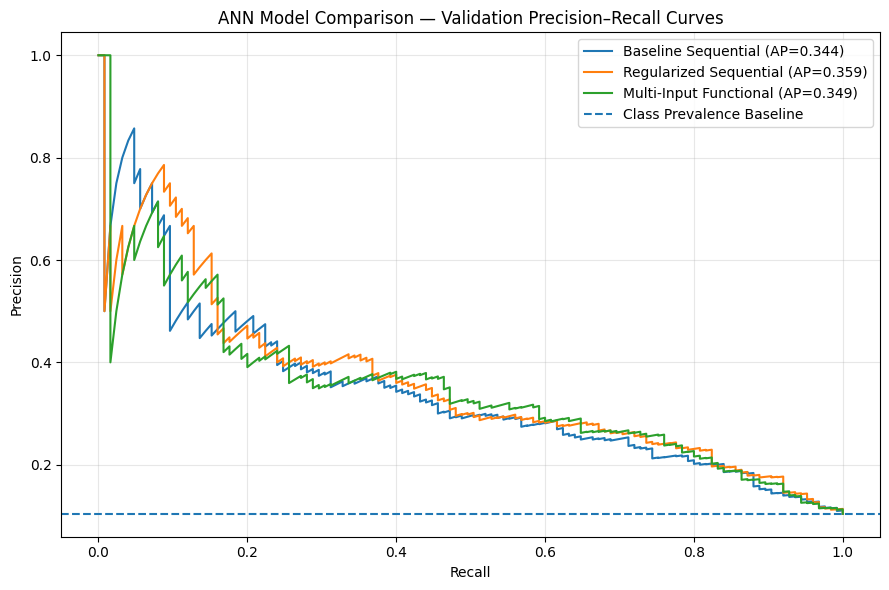

In [73]:

from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(9, 6))

models_for_pr = {
    "Baseline Sequential": val_probabilities,
    "Regularized Sequential": reg_val_probs,
    "Multi-Input Functional": multi_val_probs
}

for name, probabilities in models_for_pr.items():
    precision, recall, _ = precision_recall_curve(
        y_val_nn,
        probabilities
    )

    ap = average_precision_score(
        y_val_nn,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP={ap:.3f})"
    )

plt.axhline(
    y=y_val_nn.mean(),
    linestyle="--",
    label="Class Prevalence Baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("ANN Model Comparison — Validation Precision–Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Step 65 — Precision–Recall Curve Comparison

- Baseline Sequential AP: **0.3443**
- Regularized Sequential AP: **0.3595**
- Multi-Input Functional AP: **0.3495**
- All three models perform above the positive-class prevalence baseline of approximately 0.1042.
- The precision–recall curves intersect, indicating that relative model performance varies across recall levels.

**Conclusion:** The Regularized Sequential ANN achieves the highest overall Average Precision on validation data.

**Decision:** Retain it as the provisional preferred model. Select a classification threshold using validation data before final testing.

In [74]:

from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val_nn,
    reg_val_probs
)

# The last precision/recall pair has no corresponding threshold
threshold_table = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision[:-1],
    "Recall": recall[:-1]
})

# Apply the project-defined recall constraint
eligible = threshold_table[
    threshold_table["Recall"] >= 0.80
].copy()

if eligible.empty:
    print("No eligible threshold found.")
else:
    best_row = eligible.sort_values(
        ["Precision", "Threshold"],
        ascending=[False, False]
    ).iloc[0]

    selected_threshold = float(best_row["Threshold"])

    print("Selected Threshold:", round(selected_threshold, 4))
    print("Validation Precision:", round(best_row["Precision"], 4))
    print("Validation Recall:", round(best_row["Recall"], 4))


Selected Threshold: 0.4592
Validation Precision: 0.2327
Validation Recall: 0.808


### Step 66 — Classification Threshold Selection

**Objective:** Select a classification threshold that maximizes precision while maintaining at least 80% recall on validation data.

**Findings:**
- Selected threshold: **0.4592**
- Validation precision: **23.27%**
- Validation recall: **80.80%**
- Minimum recall requirement: **80%**

**Conclusion:** The selected threshold meets the project-defined recall requirement on validation data.

**Decision:** Use this threshold with the Regularized Sequential ANN for final evaluation. The threshold will remain fixed when evaluating the untouched test dataset.

In [75]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Apply selected threshold to validation predictions
selected_val_preds = (
    reg_val_probs >= selected_threshold
).astype(int)

# Calculate confusion matrix
cm_selected = confusion_matrix(
    y_val_nn,
    selected_val_preds,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_selected.ravel()

print("Selected Threshold:", round(selected_threshold, 4))

print("\nConfusion Matrix:")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nClassification Report:")
print(
    classification_report(
        y_val_nn,
        selected_val_preds,
        digits=4
    )
)


Selected Threshold: 0.4592

Confusion Matrix:
True Negatives: 742
False Positives: 333
False Negatives: 24
True Positives: 101

Classification Report:
              precision    recall  f1-score   support

         0.0     0.9687    0.6902    0.8061      1075
         1.0     0.2327    0.8080    0.3614       125

    accuracy                         0.7025      1200
   macro avg     0.6007    0.7491    0.5837      1200
weighted avg     0.8920    0.7025    0.7598      1200



### Step 67 — Final Validation Threshold Verification

**Selected Model:** Regularized Sequential ANN

**Classification Threshold:** 0.4592

**Validation Results:**
- Accuracy: **70.25%**
- Precision (Class 1): **23.27%**
- Recall (Class 1): **80.80%**
- F1-score (Class 1): **0.3614**
- True Positives: 101
- True Negatives: 742
- False Positives: 333
- False Negatives: 24

**Conclusion:** The selected model and threshold satisfy the project-defined 80% recall target on validation data.

The model detects most elevated-risk observations but produces many false positives.

**Decision:** Freeze the Regularized Sequential ANN and threshold of 0.4592 for final test evaluation. The recall target is not guaranteed to hold on unseen data.

In [76]:

# Final test probabilities
test_probabilities = regularized_model.predict(
    X_test_nn,
    verbose=0
).ravel()

# Apply the frozen validation-selected threshold
test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

# Final classification metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

final_test_results = {
    "Accuracy": accuracy_score(
        y_test_nn, test_predictions
    ),
    "Precision": precision_score(
        y_test_nn, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test_nn, test_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test_nn, test_predictions, zero_division=0
    ),
    "Average Precision": average_precision_score(
        y_test_nn, test_probabilities
    ),
    "ROC-AUC": roc_auc_score(
        y_test_nn, test_probabilities
    )
}

display(
    pd.DataFrame(
        [final_test_results],
        index=["Regularized Sequential ANN"]
    ).round(4)
)

print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test_nn, test_predictions))


,Accuracy,Precision,Recall,F1 Score,Average Precision,ROC-AUC
Regularized Sequential ANN,0.6858,0.2225,0.808,0.3489,0.3513,0.7943



Test Confusion Matrix:
[[722 353]
 [ 24 101]]


### Step 68 — Final Test Evaluation Findings

**Selected Model:** Regularized Sequential ANN  
**Classification Threshold:** 0.4592

**Test Confusion Matrix:**
- True Negatives: 722
- False Positives: 353
- False Negatives: 24
- True Positives: 101

**Test Performance:**
- Accuracy: **68.58%**
- Precision: **22.25%**
- Recall: **80.80%**
- F1-score: **0.3489**
- Specificity: **67.16%**

**Conclusion:** The model achieved the project-defined recall target of 80% on the untouched test dataset. However, low precision and a substantial false-positive count limit its practical usefulness.

These findings apply to the synthetic dataset and do not establish clinical reliability.

In [77]:

print(
    "Test Average Precision:",
    round(final_test_results["Average Precision"], 4)
)

print(
    "Test ROC-AUC:",
    round(final_test_results["ROC-AUC"], 4)
)


Test Average Precision: 0.3513
Test ROC-AUC: 0.7943


### Step 69 — Final Test Evaluation Summary

**Selected Model:** Regularized Sequential ANN  
**Classification Threshold:** 0.4592

**Final Test Performance:**
- Accuracy: **68.58%**
- Precision: **22.25%**
- Recall: **80.80%**
- F1-score: **0.3489**
- Average Precision: **0.3513**
- ROC-AUC: **0.7943**

**Findings:**
- The model correctly detected 101 of 125 elevated-risk test records.
- Validation and test ranking metrics were relatively close.
- Precision remained low because of the substantial number of false positives.
- The test recall met the project's predefined 80% target.

**Conclusion:** The selected ANN demonstrates useful discrimination on held-out synthetic data, with recall prioritized over precision. These results do not establish real-world clinical reliability.

The final evaluation is complete. No further model or threshold tuning will be performed using the test results.

In [78]:

from pathlib import Path
import joblib
import json

# Project folders
project_root = Path.cwd().parent
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Save trained ANN
regularized_model.save(
    str(models_dir / "regularized_sequential_ann.keras")
)

# Save fitted preprocessor
joblib.dump(
    preprocessor,
    models_dir / "preprocessor.joblib"
)

# Save threshold and metadata
metadata = {
    "selected_model": "Regularized Sequential ANN",
    "threshold": float(selected_threshold),
    "input_features": list(X_train.columns),
    "processed_feature_count": int(X_train_nn.shape[1]),
    "tensorflow_version": tf.__version__
}

with open(models_dir / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Model artifacts saved to:", models_dir)
print("Saved files:")
for path in sorted(models_dir.iterdir()):
    print("-", path.name)


Model artifacts saved to: c:\Users\madhu\Desktop\models
Saved files:
- model_metadata.json
- preprocessor.joblib
- regularized_sequential_ann.keras


### Step 70 — Model Artifact Saving

- Trained ANN saved in Keras `.keras` format.
- Fitted preprocessing pipeline saved using Joblib.
- Selected classification threshold and input metadata saved in JSON format.
- Three model artifacts were successfully created.

**Finding:** The files were saved outside the project directory because the notebook's working directory differed from the assumed directory.

**Next Action:** Move the artifacts into the project's `models/` folder and verify that they can be reloaded successfully.

In [79]:

from pathlib import Path
import shutil

project_root = Path(
    r"C:\Users\madhu\Desktop\cardiometabolic-risk-prediction-ann"
)

source_dir = Path(r"C:\Users\madhu\Desktop\models")
destination_dir = project_root / "models"

destination_dir.mkdir(parents=True, exist_ok=True)

artifact_names = [
    "regularized_sequential_ann.keras",
    "preprocessor.joblib",
    "model_metadata.json"
]

for filename in artifact_names:
    source = source_dir / filename
    destination = destination_dir / filename

    if source.exists():
        shutil.copy2(source, destination)
        print("Copied:", destination)
    else:
        print("Source missing:", source)

print("\nVerification:")
for filename in artifact_names:
    file_path = destination_dir / filename
    print(filename, "Exists:", file_path.is_file())


Copied: C:\Users\madhu\Desktop\cardiometabolic-risk-prediction-ann\models\regularized_sequential_ann.keras
Copied: C:\Users\madhu\Desktop\cardiometabolic-risk-prediction-ann\models\preprocessor.joblib
Copied: C:\Users\madhu\Desktop\cardiometabolic-risk-prediction-ann\models\model_metadata.json

Verification:
regularized_sequential_ann.keras Exists: True
preprocessor.joblib Exists: True
model_metadata.json Exists: True


### Step 71 — Model Artifact Organization

- Trained ANN saved as `regularized_sequential_ann.keras`.
- Fitted preprocessing pipeline saved as `preprocessor.joblib`.
- Classification threshold and feature metadata saved as `model_metadata.json`.
- All three files successfully copied into the project's `models/` directory.
- File existence verification passed.

**Conclusion:** The trained model and its required preprocessing artifacts are organized correctly and ready for reloading.

In [80]:

import json
import joblib
import numpy as np
from tensorflow import keras

# Load saved artifacts
loaded_model = keras.models.load_model(
    str(destination_dir / "regularized_sequential_ann.keras")
)

loaded_preprocessor = joblib.load(
    destination_dir / "preprocessor.joblib"
)

with open(destination_dir / "model_metadata.json", "r") as f:
    loaded_metadata = json.load(f)

# Select five raw validation records
sample_records = X_val.iloc[:5]

# Apply saved preprocessing
sample_processed = loaded_preprocessor.transform(
    sample_records
).astype(np.float32)

# Predict using the loaded model
loaded_probabilities = loaded_model.predict(
    sample_processed,
    verbose=0
).ravel()

# Compare against the original model
original_probabilities = regularized_model.predict(
    X_val_nn[:5],
    verbose=0
).ravel()

print("Loaded Threshold:", loaded_metadata["threshold"])

print("\nOriginal Probabilities:")
print(np.round(original_probabilities, 4))

print("\nLoaded Probabilities:")
print(np.round(loaded_probabilities, 4))

print(
    "\nPredictions Match:",
    np.allclose(
        original_probabilities,
        loaded_probabilities,
        atol=1e-6
    )
)


Loaded Threshold: 0.45922309160232544

Original Probabilities:
[0.0307 0.5837 0.0159 0.2791 0.9008]

Loaded Probabilities:
[0.0307 0.5837 0.0159 0.2791 0.9008]

Predictions Match: True


## 7. Project Conclusion

### Project Summary

Developed and evaluated Artificial Neural Network models using TensorFlow and Keras to classify cardiometabolic risk using a synthetic dataset containing 8,000 records and 13 input features.

### Models Implemented

1. Baseline Sequential ANN
2. Regularized Sequential ANN (L2 + Dropout)
3. Single-Input Functional ANN
4. Multi-Input Functional ANN

### Key Findings

- Data quality checks identified no missing values, exact duplicates, infinite values or invalid category codes.
- Potential numerical outliers were retained because extreme health measurements may contain predictive information.
- Stratified train-validation-test splitting preserved the imbalanced target distribution.
- Sequential and equivalent single-input Functional ANNs produced identical predictions.
- The Regularized Sequential ANN achieved the highest validation Average Precision among the evaluated models.
- The Multi-Input Functional ANN demonstrated the ability to learn from separate feature branches.

### Final Selected Model

**Regularized Sequential ANN**

**Selected Threshold:** 0.4592

| Test Metric | Result |
|---|---:|
| Accuracy | 68.58% |
| Precision | 22.25% |
| Recall | 80.80% |
| F1-score | 0.3489 |
| Average Precision | 0.3513 |
| ROC-AUC | 0.7943 |

### Limitations

- The dataset is synthetic and not clinically validated.
- The target-generation formula is undocumented.
- Precision remains low, resulting in many false-positive predictions.
- Model comparisons were performed using a single data split and training run.
- Predictions must not be used for medical diagnosis or real-world clinical decision-making.

### Final Outcome

Successfully implemented and compared Sequential and Functional ANN architectures, evaluated classification performance, selected a validation-based threshold, and saved a reproducible model and preprocessing pipeline.

**Project Status:** Completed for the intended TensorFlow/Keras learning objectives.